# 0. Preparation and Global Definition

In [13]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
import torch
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from data_provider.dataset import process_ms_spectra_for_wcs
from analyzer.core import auto_eval_topk, get_data_and_features, get_cos_distance, get_topk_acc, find_functional_group_pairs, plot_mol_structure, plot_distance_curve
matplotlib.rcParams['font.family'] = 'Times New Roman'
pd.set_option('display.unicode.east_asian_width', True)
pd.set_option('display.unicode.ambiguous_as_wide', True)
pd.set_option('display.max_colwidth', None)

# config_path = "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-02-08_155340/config_2026-02-08_155340.json"
# ablation_study_paths = [
#     "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm0_se0_2026-02-11_204925/config_2026-02-11_204925.json",
#     "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm0_se1_2026-02-11_124340/config_2026-02-11_124340.json",
#     "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm1_se1_2026-02-10_123237/config_2026-02-10_123237.json",
#     config_path
# ]
config_path17 = "results/CSUEI_nist17_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-03-27_150000/config_2026-03-27_150000.json"
config_path = "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-02-13_193603/config_2026-02-13_193603.json"
optimizing_study_paths = [
    "results/baseline_2026-10-08_234149/config_2026-10-08_234149.json",
    "results/baseline_2026-10-08_232706/config_2026-10-08_232706.json",
    "results/baseline_2026-10-09_090354/config_2026-10-09_090354.json",

    "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm0_se0_2026-10-08_145154/config_2026-10-08_145154.json",
    "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm0_se1_2026-02-18_100828/config_2026-02-18_100828.json",
    "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm1_se1_2026-02-18_100716/config_2026-02-18_100716.json",
    config_path
]
ablation_study_paths = [
    # "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm0_se0_2026-02-18_100902/config_2026-02-18_100902.json",
    "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm0_se0_2026-10-08_145154/config_2026-10-08_145154.json",
    "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm0_se1_2026-02-18_100828/config_2026-02-18_100828.json",
    "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa0_msesa0_rm1_se1_2026-02-18_100716/config_2026-02-18_100716.json",
    config_path
]


exp_dir = os.path.dirname(config_path)
time_stamp = '_'.join(exp_dir.split('_')[-2:])
# Define save directory
save_dir = os.path.join(exp_dir, "plot_result_analyzer")
os.makedirs(save_dir, exist_ok=True)
save_dir = None 

# 1. Optimizing CSU-EI

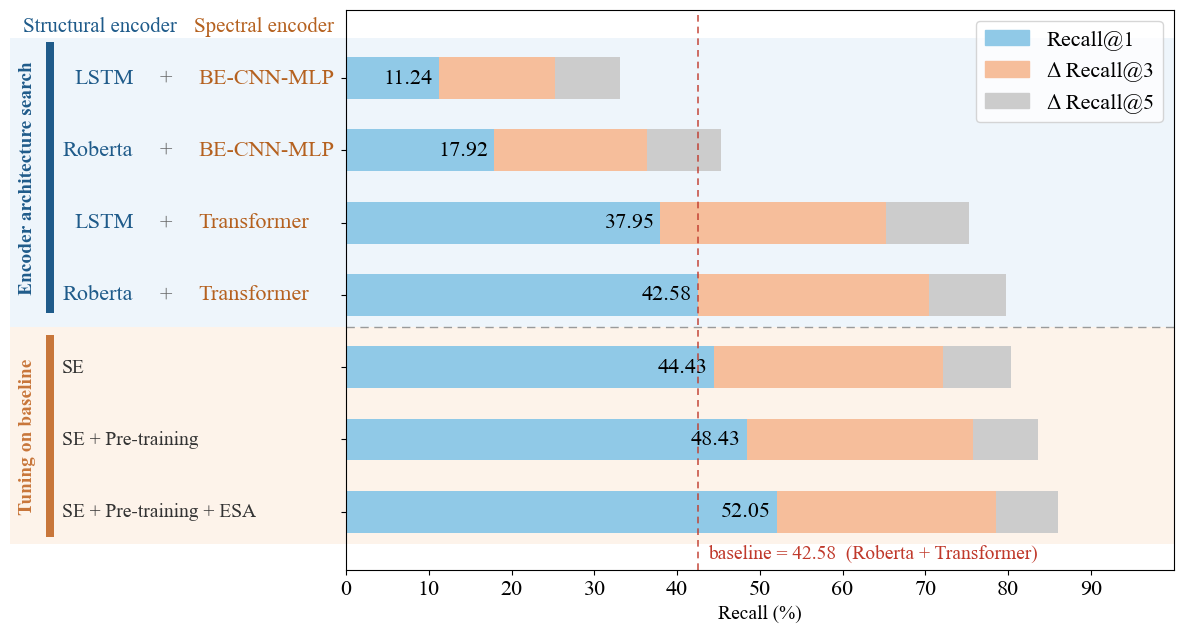

In [6]:
import matplotlib.transforms as mtransforms
from matplotlib.patches import Rectangle, Patch

labels = [
    'LSTM + BE-CNN-MLP',
    'Roberta + BE-CNN-MLP',
    'LSTM + Transformer',
    'Roberta + Transformer',
    'SE',
    'SE + Pre-training',
    'SE + Pre-training + ESA'
]
k_list = ['1', '3', '5']
# Read metrics
data_all = np.array([get_topk_acc(p, k_list, mode='dev')[0] for p in optimizing_study_paths])
seg_r1, seg_d3, seg_d5 = data_all[:,0], data_all[:,1]-data_all[:,0], data_all[:,2]-data_all[:,1]
segments = np.stack([seg_r1, seg_d3, seg_d5], axis=-1)
colors = ['#90c9e7', "#f6be9b", '#cccccc']

fig, ax = plt.subplots(figsize=(12,7))
# Background bands
BAND_A, BAND_B = "#eef5fb", "#fdf3ea"
tr_bg = mtransforms.blended_transform_factory(fig.transFigure, ax.transData)
ax.add_patch(Rectangle((0.0, 2.55), 0.97, 6.55-2.55, transform=tr_bg, facecolor=BAND_A, ec="none", zorder=0.2, clip_on=False))
ax.add_patch(Rectangle((0.0, -0.45), 0.97, 2.55+0.45, transform=tr_bg, facecolor=BAND_B, ec="none", zorder=0.2, clip_on=False))
ax.axhline(2.55, color="#9a9a9a", lw=1.0, ls=(0,(6,4)), zorder=0.7)

y_pos = np.arange(len(labels))[::-1]
left_offset = np.zeros(len(labels))
min_thresh = 6

for seg_idx in range(3):
    ax.barh(y_pos, segments[:,seg_idx], left=left_offset, height=0.58, color=colors[seg_idx])
    if seg_idx == 0:
        for i,y in enumerate(y_pos):
            val = seg_r1[i]
            if val > min_thresh:
                x_txt, ha = left_offset[i]+val-0.75, 'right'
            else:
                x_txt, ha = left_offset[i]+val+1.0, 'left'
            ax.text(x_txt, y, f"{val:.2f}", va="center", ha=ha, fontfamily='Times New Roman', fontsize=16, c="black")
    left_offset += segments[:,seg_idx]

# Baseline vertical line
base = seg_r1[3]
ax.axvline(base, color='#c0392b', lw=1.2, ls=(0,(4,3)), alpha=0.85, zorder=2)
ax.text(base+1.2, -0.58, f"baseline = {base:.2f}  (Roberta + Transformer)",
        fontfamily='Times New Roman', fontsize=14, c='#c0392b', va="center", ha="left", zorder=6)

# Custom y labels
ax.set_yticks(y_pos)
ax.set_yticklabels([])
tab = mtransforms.blended_transform_factory(fig.transFigure, ax.transData)
X_F_COL, X_MID, X_GAP = 0.043, 0.130, 0.027
mol, spec = ["LSTM","Roberta","LSTM","Roberta"], ["BE-CNN-MLP","BE-CNN-MLP","Transformer","Transformer"]
for yi, m, s in zip(y_pos[:4], mol, spec):
    ax.text(X_MID-X_GAP, yi, m, transform=tab, ha="right", va="center", fontfamily='Times New Roman', fontsize=16, c='#1f5b8a', zorder=5, clip_on=False)
    ax.text(X_MID, yi, "+", transform=tab, ha="center", va="center", fontfamily='Times New Roman', fontsize=16, c='#666666', zorder=5, clip_on=False)
    ax.text(X_MID+X_GAP, yi, s, transform=tab, ha="left", va="center", fontfamily='Times New Roman', fontsize=16, c='#b5611f', zorder=5, clip_on=False)
grpB = ["SE", "SE + Pre-training", "SE + Pre-training + ESA"]
for yi, name in zip(y_pos[4:], grpB):
    ax.text(X_F_COL, yi, name, transform=tab, ha="left", va="center", fontfamily='Times New Roman', fontsize=14, c='#333333', zorder=5, clip_on=False)

# Column headers
ax.text(0.075, 6.72, "Structural encoder", transform=tab, ha="center", va="center", fontfamily='Times New Roman', fontsize=15, c='#1f5b8a', zorder=6, clip_on=False)
ax.text(0.212, 6.72, "Spectral encoder", transform=tab, ha="center", va="center", fontfamily='Times New Roman', fontsize=15, c='#b5611f', zorder=6, clip_on=False)

# Group marker helper
tr = mtransforms.blended_transform_factory(fig.transFigure, ax.transData)
def add_group_mark(y_lo, y_hi, accent, title, fx=0.030, bw=0.007):
    ax.add_patch(Rectangle((fx, y_lo), bw, y_hi-y_lo, transform=tr, facecolor=accent, ec="none", clip_on=False, zorder=6))
    ax.text(fx-0.015, 0.5*(y_lo+y_hi), title, transform=tr, rotation=90, ha="center", va="center",
            fontfamily='Times New Roman', fontsize=14, fontweight="bold", c=accent, clip_on=False)
add_group_mark(2.75, 6.50, '#1f5b8a', "Encoder architecture search")
add_group_mark(-0.35, 2.45, '#c8763a', "Tuning on baseline")

# Axes style
ax.set_ylim(-0.80, 6.95)
ax.set_xlim(0, np.max(data_all[:,2])+14)
ax.set_xlabel('Recall (%)', fontfamily='Times New Roman', fontsize=14)
ax.set_xticks(np.arange(0,100,10))
plt.setp(ax.get_xticklabels(), fontfamily='Times New Roman', fontsize=16)

# Legend
leg = [Patch(color=colors[0], label='Recall@1'), Patch(color=colors[1], label='Δ Recall@3'), Patch(color=colors[2], label='Δ Recall@5')]
ax.legend(handles=leg, loc='best', prop={'family':'Times New Roman', 'size':16})

plt.tight_layout()
plt.subplots_adjust(left=0.28, right=0.97, top=0.92, bottom=0.12)
plt.show()

# 1. Ablation Study

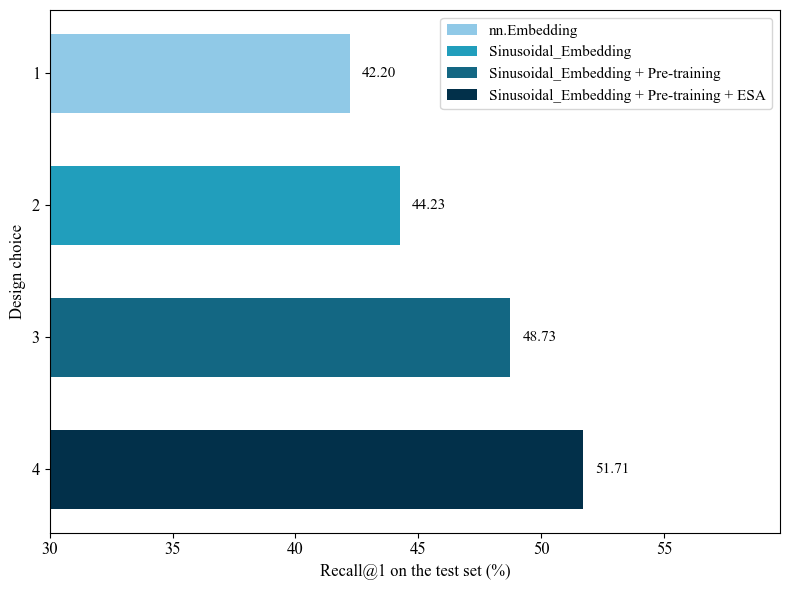

In [4]:
labels = [
    'nn.Embedding', 
    'Sinusoidal_Embedding', 
    'Sinusoidal_Embedding + Pre-training', 
    'Sinusoidal_Embedding + Pre-training + ESA'
]

# Retrieve Top-1 Accuracy
# Corrected list comprehension: iterate 'p' over 'ablation_study_paths'
values = np.array([get_topk_acc(p, k_list=['1'])[0][0] for p in ablation_study_paths])
# Plotting
plt.figure(figsize=(8, 6))
colors, y_pos = ['#02304a', '#136783', '#219ebc', '#90c9e7'], range(len(labels))
bars = plt.barh(y_pos, values[::-1], color=colors, label=labels[::-1], height=0.6)
# Styling
plt.xlim(30, max(values) + 8)
plt.xticks(np.arange(30, 60, 5), fontsize=12, fontname='Times New Roman')
plt.yticks(y_pos, [4, 3, 2, 1], fontsize=12, fontname='Times New Roman')
plt.xlabel('Recall@1 on the test set (%)', fontsize=12, fontname='Times New Roman')
plt.ylabel('Design choice', fontsize=12, fontname='Times New Roman')
# Annotations
for bar in bars:
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f'{bar.get_width():.2f}', 
             va='center', ha='left', fontsize=11, fontname='Times New Roman')
# Legend
handles, lbls = plt.gca().get_legend_handles_labels()
plt.legend(handles[::-1], lbls[::-1], prop={'family': 'Times New Roman', 'size': 11}, loc='upper right')
plt.tight_layout() 
plt.show()

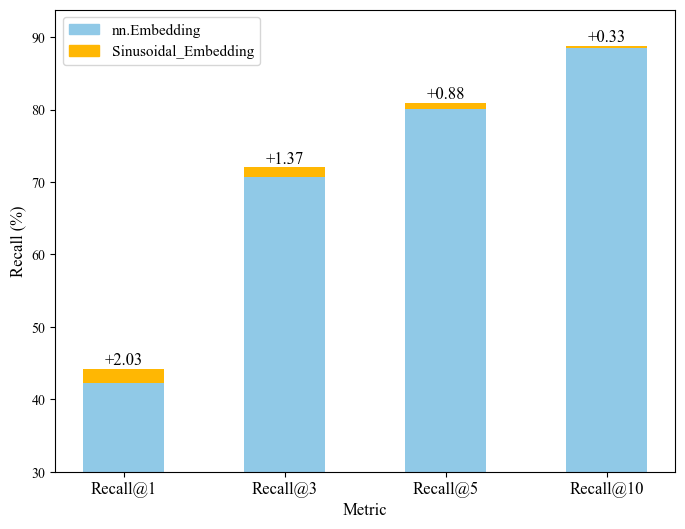

In [9]:
# Simplified Performance Comparison
k_list = ['1', '3', '5', '10']

# 1. Fetch & Prepare Data
# vals shape: (2 models, n metrics)
vals = np.array([get_topk_acc(p, k_list)[0] for p in ablation_study_paths[0:2]])
base_model_acc = vals[0]
comp_model_acc = vals[1]
gains = comp_model_acc - base_model_acc

# 2. Plotting
plt.figure(figsize=(8, 6))

# Plot Baseline Bars (The reference model)
plt.bar(k_list, base_model_acc, width=0.5, label=labels[0], color='#90c9e7')

# Plot Difference Stack
# Logic: 
# - Positive gain: Start at base, go up (Color: Dark Blue)
# - Negative gain (Drop): Start at base, go down (Color: Orange)
colors = [ '#ffb703'if g >= 0 else '#219ebc' for g in gains]
plt.bar(k_list, gains, width=0.5, bottom=base_model_acc, color=colors)

# 3. Styling & Annotations
# Add a dummy handle for the second model label (simplifies legend)
from matplotlib.patches import Patch
legend_handles = [Patch(color='#90c9e7', label=labels[0]),
                  Patch(color='#ffb703', label=labels[1])]

for i, g in enumerate(gains):
    va = 'bottom' if g >= 0 else 'top'
    y_pos = base_model_acc[i] + g if g >= 0 else base_model_acc[i] + g - 0.5
    plt.text(i, y_pos, f'{g:+.2f}', ha='center', va=va, fontsize=12, fontname='Times New Roman')

plt.ylabel('Recall (%)', fontname='Times New Roman', fontsize=12)
plt.ylim(30, np.max(vals) + 5)
plt.legend(handles=legend_handles, prop={'family': 'Times New Roman', 'size': 11}, loc='upper left')
plt.xlabel('Metric', fontname='Times New Roman', fontsize=12)
plt.xticks(range(len(k_list)), [f'Recall@{k}' for k in k_list], fontname='Times New Roman', fontsize=12)
plt.show()

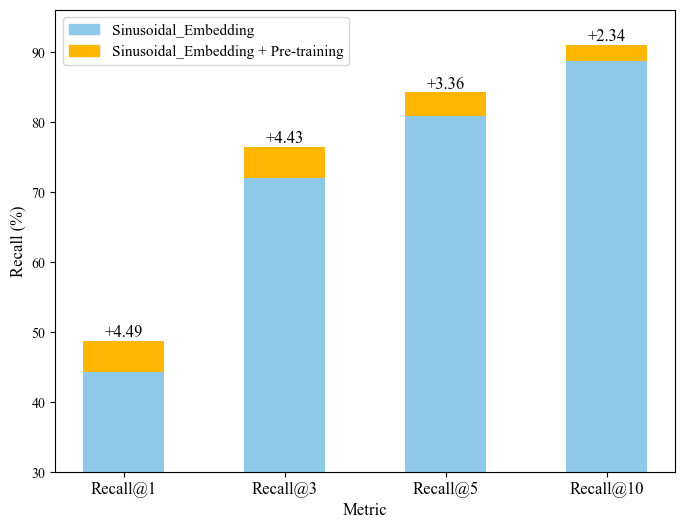

In [11]:
# 1. Fetch & Prepare Data
# vals shape: (2 models, n metrics)
vals = np.array([get_topk_acc(p, k_list)[0] for p in ablation_study_paths[1:3]])
base_model_acc = vals[0]
comp_model_acc = vals[1]
gains = comp_model_acc - base_model_acc

# 2. Plotting
plt.figure(figsize=(8, 6))

# Plot Baseline Bars (The reference model)
plt.bar(k_list, base_model_acc, width=0.5, label=labels[1], color='#90c9e7')

# Plot Difference Stack
# Logic: 
# - Positive gain: Start at base, go up (Color: Dark Blue)
# - Negative gain (Drop): Start at base, go down (Color: Orange)
colors = [ '#ffb703'if g >= 0 else '#219ebc' for g in gains]
plt.bar(k_list, gains, width=0.5, bottom=base_model_acc, color=colors)

# 3. Styling & Annotations
# Add a dummy handle for the second model label (simplifies legend)
from matplotlib.patches import Patch
legend_handles = [Patch(color='#90c9e7', label=labels[1]),
                  Patch(color='#ffb703', label=labels[2])]

for i, g in enumerate(gains):
    va = 'bottom' if g >= 0 else 'top'
    y_pos = base_model_acc[i] + g if g >= 0 else base_model_acc[i] + g - 0.5
    plt.text(i, y_pos, f'{g:+.2f}', ha='center', va=va, fontsize=12, fontname='Times New Roman')

plt.ylabel('Recall (%)', fontname='Times New Roman', fontsize=12)
plt.ylim(30, np.max(vals) + 5)
plt.legend(handles=legend_handles, prop={'family': 'Times New Roman', 'size': 11}, loc='upper left')
plt.xlabel('Metric', fontname='Times New Roman', fontsize=12)
plt.xticks(range(len(k_list)), [f'Recall@{k}' for k in k_list], fontname='Times New Roman', fontsize=12)
plt.show()

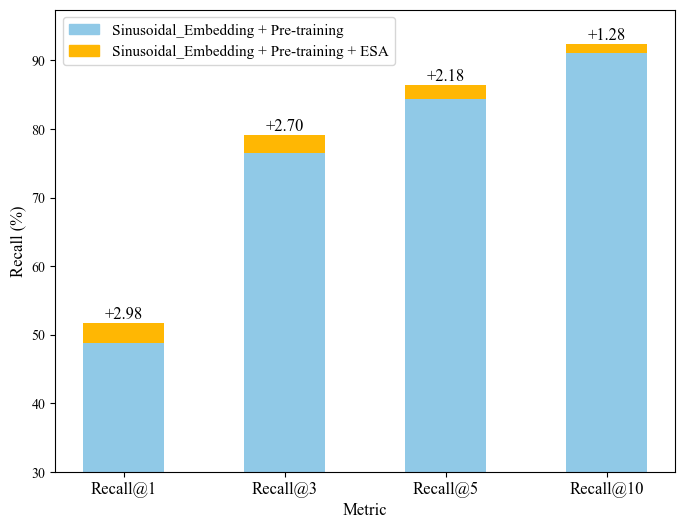

In [12]:
# 1. Fetch & Prepare Data
# vals shape: (2 models, n metrics)
vals = np.array([get_topk_acc(p, k_list)[0] for p in ablation_study_paths[2:4]])
base_model_acc = vals[0]
comp_model_acc = vals[1]
gains = comp_model_acc - base_model_acc

# 2. Plotting
plt.figure(figsize=(8, 6))

# Plot Baseline Bars (The reference model)
plt.bar(k_list, base_model_acc, width=0.5, label=labels[2], color='#90c9e7')

# Plot Difference Stack
# Logic: 
# - Positive gain: Start at base, go up (Color: Dark Blue)
# - Negative gain (Drop): Start at base, go down (Color: Orange)
colors = [ '#ffb703'if g >= 0 else '#219ebc' for g in gains]
plt.bar(k_list, gains, width=0.5, bottom=base_model_acc, color=colors)

# 3. Styling & Annotations
# Add a dummy handle for the second model label (simplifies legend)
from matplotlib.patches import Patch
legend_handles = [Patch(color='#90c9e7', label=labels[2]),
                  Patch(color='#ffb703', label=labels[3])]

for i, g in enumerate(gains):
    va = 'bottom' if g >= 0 else 'top'
    y_pos = base_model_acc[i] + g if g >= 0 else base_model_acc[i] + g - 0.5
    plt.text(i, y_pos, f'{g:+.2f}', ha='center', va=va, fontsize=12, fontname='Times New Roman')

plt.ylabel('Recall (%)', fontname='Times New Roman', fontsize=12)
plt.ylim(30, np.max(vals) + 5)
plt.legend(handles=legend_handles, prop={'family': 'Times New Roman', 'size': 11}, loc='upper left')
plt.xlabel('Metric', fontname='Times New Roman', fontsize=12)
plt.xticks(range(len(k_list)), [f'Recall@{k}' for k in k_list], fontname='Times New Roman', fontsize=12)
plt.show()

# 2. Evaluation and Comparison

## 2.1 UMAP

In [5]:
import umap
with open("data/nist23_data/test23/test.json", "r", encoding="utf-8") as f:
    data = json.load(f)
df = pd.DataFrame(data)
test_data = (df["smiles"].values.tolist(), df["peaks"].values.tolist())

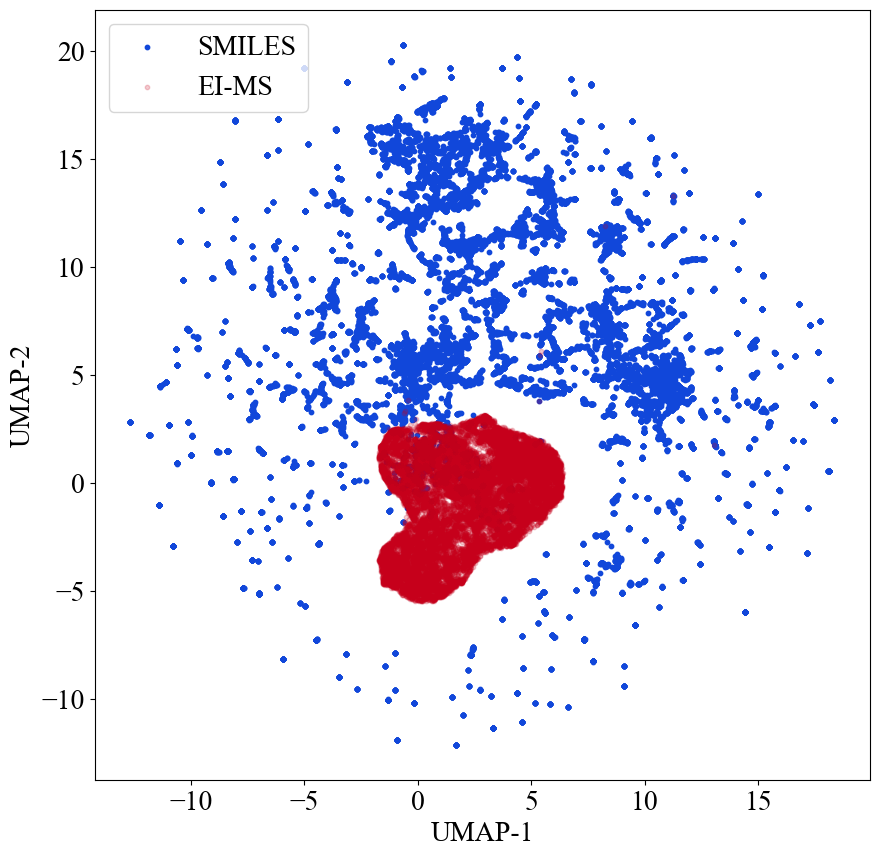

In [3]:
_, all_feature = get_data_and_features(config_path, test_data, batch_size=256, epoch=1)
smiles_feature, ms_feature, similarity, _, _ = all_feature
reducer = umap.UMAP(n_components=2)
feature = np.concatenate([smiles_feature.cpu().numpy(), ms_feature.cpu().numpy()], axis=0)
len1 = smiles_feature.shape[0]
# print(feature.shape)
feature = reducer.fit_transform(feature)
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(feature[:len1, 0], feature[:len1, 1], color='#1147da', label='SMILES', s=10)
ax.scatter(feature[len1:, 0], feature[len1:, 1], color='#c6001b', label='EI-MS', s=10, alpha=0.2)

# Connect paired data points with lines
# for i in range(len1):
#     ax.plot([feature[i, 0], feature[len1 + i, 0]], [feature[i, 1], feature[len1 + i, 1]], color='gray', linestyle='-', linewidth=0.25, alpha=0.75)

ax.legend(prop={'family': 'times new roman', 'size': 20}, loc='upper left')
ax.set_ylabel('UMAP-2', fontsize=20, fontname='times new roman')
ax.set_xlabel('UMAP-1', fontsize=20, fontname='times new roman')
ax.tick_params(axis='both', which='major', labelsize=20)
if save_dir is not None:
    save_path = os.path.join(save_dir, 'UMAP_epoch1.png')
    plt.savefig(save_path, dpi=300)
plt.show()

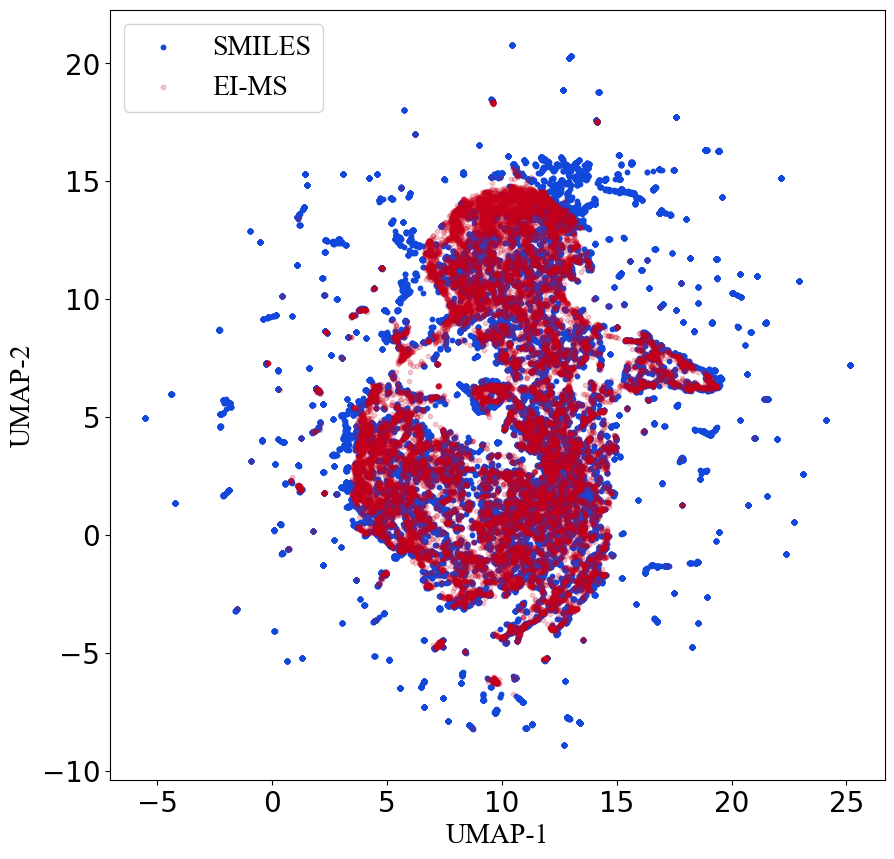

In [3]:
_, all_feature = get_data_and_features(config_path, test_data, batch_size=256, epoch=3)
smiles_feature, ms_feature, similarity, _, _ = all_feature
reducer = umap.UMAP(n_components=2)
feature = np.concatenate([smiles_feature.cpu().numpy(), ms_feature.cpu().numpy()], axis=0)
len1 = smiles_feature.shape[0]
# print(feature.shape)
feature = reducer.fit_transform(feature)
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(feature[:len1, 0], feature[:len1, 1], color='#1147da', label='SMILES', s=10)
ax.scatter(feature[len1:, 0], feature[len1:, 1], color='#c6001b', label='EI-MS', s=10, alpha=0.2)

# Connect paired data points with lines
# for i in range(len1):
#     ax.plot([feature[i, 0], feature[len1 + i, 0]], [feature[i, 1], feature[len1 + i, 1]], color='gray', linestyle='-', linewidth=0.25, alpha=0.75)

ax.legend(prop={'family': 'times new roman', 'size': 20}, loc='upper left')
ax.set_ylabel('UMAP-2', fontsize=20, fontname='times new roman')
ax.set_xlabel('UMAP-1', fontsize=20, fontname='times new roman')
ax.tick_params(axis='both', which='major', labelsize=20)
if save_dir is not None:
    save_path = os.path.join(save_dir, 'UMAP_epoch3.png')
    plt.savefig(save_path, dpi=300)
plt.show()

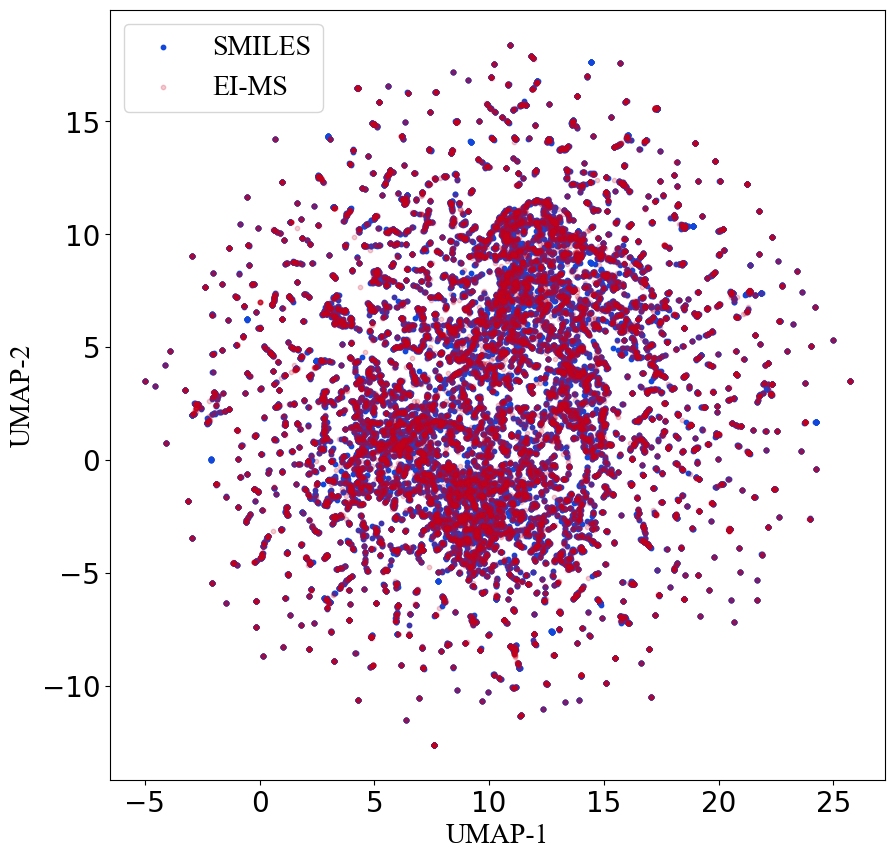

In [ ]:
_, all_feature = get_data_and_features(config_path, test_data, batch_size=256)
smiles_feature, ms_feature, similarity, _, _ = all_feature

reducer = umap.UMAP(n_components=2)
feature = np.concatenate([smiles_feature.cpu().numpy(), ms_feature.cpu().numpy()], axis=0)
len1 = smiles_feature.shape[0]
# print(feature.shape)
feature = reducer.fit_transform(feature)
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(feature[:len1, 0], feature[:len1, 1], color='#1147da', label='SMILES', s=10)
ax.scatter(feature[len1:, 0], feature[len1:, 1], color='#c6001b', label='EI-MS', s=10, alpha=0.2)

# Connect paired data points with lines
# for i in range(len1):
#     ax.plot([feature[i, 0], feature[len1 + i, 0]], [feature[i, 1], feature[len1 + i, 1]], color='gray', linestyle='-', linewidth=0.25, alpha=0.75)

ax.legend(prop={'family': 'times new roman', 'size': 20}, loc='upper left')
ax.set_ylabel('UMAP-2', fontsize=20, fontname='times new roman')
ax.set_xlabel('UMAP-1', fontsize=20, fontname='times new roman')
ax.tick_params(axis='both', which='major', labelsize=20)
if save_dir is not None:
    save_path = os.path.join(save_dir, 'UMAP_UMAP_epoch100.png')
    plt.savefig(save_path, dpi=300)
plt.show()

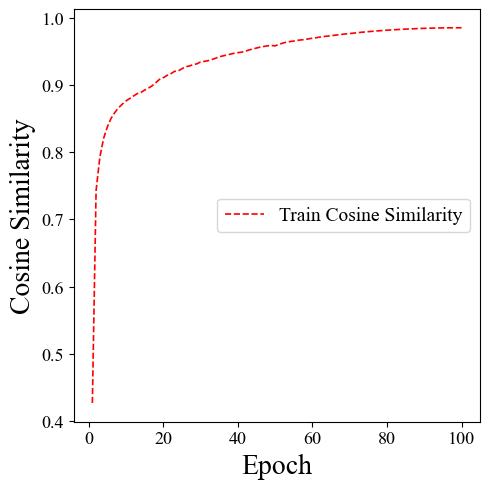

In [2]:
plot_distance_curve("results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-07-20_140048/loss_record/loss_record_2026-07-20_140048.csv", save_dir)

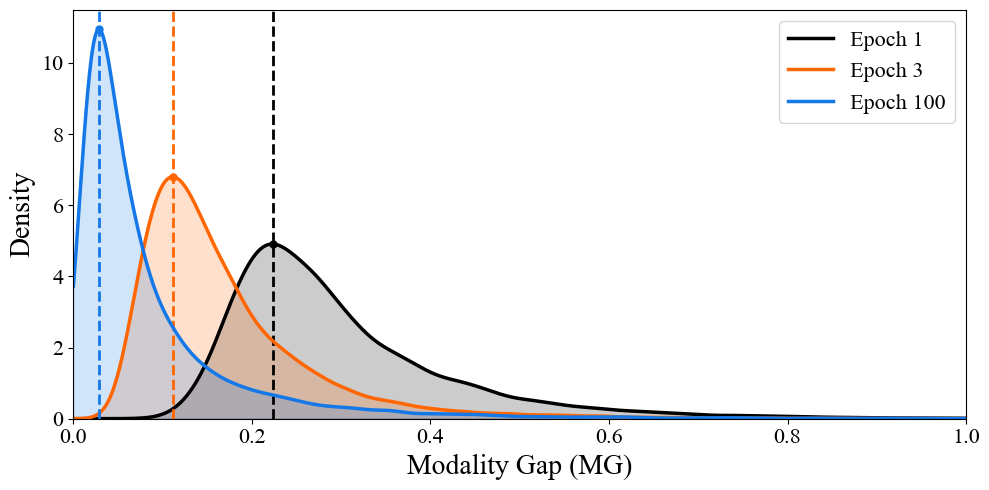

In [7]:
from scipy.stats import gaussian_kde
import gc

epochs = [1, 3, None]
colors = ["black", "#ff6600", "#1478e8"]
label_map = {1:"Epoch 1",3:"Epoch 3",None:"Epoch 100"}
chunk_size = 4096

plt.figure(figsize=(10, 5))
for raw_epoch, color in zip(epochs, colors):
    paired_sim = []
    total = len(test_data[0])
    for start in range(0, total, chunk_size):
        end = min(start + chunk_size, total)
        _, feat = get_data_and_features(
            config_path,
            (test_data[0][start:end], test_data[1][start:end]),
            batch_size=256,
            epoch=raw_epoch,
        )
        _, _, sim, _, _ = feat
        paired_sim.append(np.diag(sim).astype(np.float32))
        del feat, sim
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    mgap = 1.0 - np.concatenate(paired_sim)
    mgap = mgap[np.isfinite(mgap)]
    x = np.linspace(0, 1, 1000)
    kde = gaussian_kde(mgap)
    dens = kde(x)
    idx_peak = np.argmax(dens)
    mode_mg = x[idx_peak]
    peak_density_val = dens[idx_peak]

    plt.plot(x, dens, color=color, lw=2.5, label=label_map[raw_epoch])
    plt.fill_between(x, dens, color=color, alpha=0.2)
    plt.axvline(mode_mg, color=color, ls="--", lw=2)
    plt.scatter(mode_mg, peak_density_val, color=color, s=25, zorder=5)

plt.xlabel("Modality Gap (MG)", fontsize=20)
plt.ylabel("Density", fontsize=20)
plt.xlim((0, 1))
plt.ylim(bottom=0)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16, loc="best")
plt.tight_layout()

if save_dir is not None:
    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(
        os.path.join(save_dir, "modality_gap_by_epoch.png"),
        dpi=300,
        bbox_inches="tight"
    )
plt.show()

## 2.2 Recall_Comparison

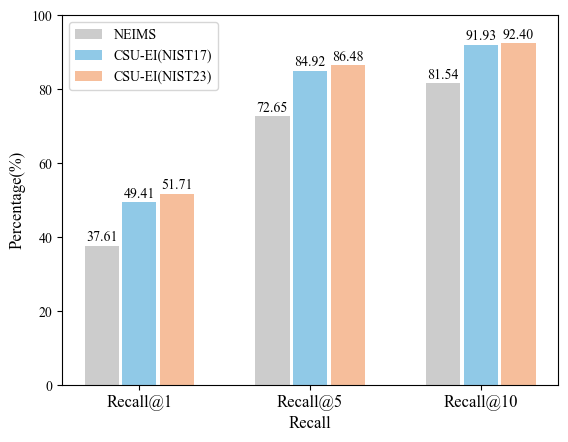

In [2]:
# Hardcoded data (Default fallback)
neims_data = [37.61, 72.65, 81.54]
nist17_data, _ = get_topk_acc(config_path17)
nist23_data, _ = get_topk_acc(config_path)

# Prepare data for plotting
methods = ['NEIMS', 'CSU-EI(NIST17)', 'CSU-EI(NIST23)']
# recall_data shape: (3, 3) -> Rows: Recall@1, @5, @10; Cols: Methods
recall_data = np.array([neims_data, nist17_data, nist23_data]).T
x_labels = ['Recall@1', 'Recall@5', 'Recall@10']

# Plotting
bar_width = 0.2
index = np.arange(len(x_labels))
fig, ax = plt.subplots()

colors = ["#cccccc", '#90c9e7', '#f6be9b']

bars1 = ax.bar(index - bar_width-0.02, recall_data[:, 0], bar_width, label='NEIMS', color=colors[0])
bars2 = ax.bar(index, recall_data[:, 1], bar_width, label='CSU-EI(NIST17)', color=colors[1])
bars3 = ax.bar(index + bar_width+0.02, recall_data[:, 2], bar_width, label='CSU-EI(NIST23)', color=colors[2])


ax.set_xlabel('Recall', fontsize=12, fontname='times new roman')
ax.set_ylabel('Percentage(%)', fontsize=12, fontname='times new roman')
ax.set_xticks(index)
ax.set_xticklabels(x_labels, fontsize=12, fontname='times new roman')
ax.set_ylim(0, 100) 
ax.legend(fontsize=12, prop={'family': 'times new roman'})


for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height + 0.5, f'{height:.2f}', ha='center', va='bottom', fontsize=10, fontname='times new roman')

if save_dir is not None:
    save_path = os.path.join(save_dir, 'Recall_Comparison_Bar.png')
    plt.savefig(save_path, dpi=300)

plt.show()

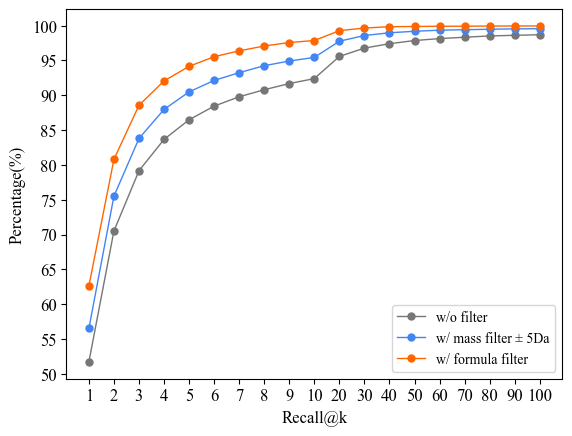

In [3]:
# Find the csv file
_, df = get_topk_acc(config_path)
x_ticks = [int(col) for col in df.columns]
x = np.arange(1, len(x_ticks) + 1)
# y1: CSUEI without filter
y1 = df.loc['w/o filter'].values * 100
# y2: CSUEI with mass filter
y2 = df.loc['w/ mass filter ± 5Da'].values * 100
# y3: CSUEI with formula filter
y3 = df.loc['w/ formula filter'].values * 100

plt.xlabel('Recall@k', fontsize=12, fontname='times new roman')
plt.ylabel('Percentage(%)', fontsize=12, fontname='times new roman')
plt.xticks(x, x_ticks, fontsize=12, fontname='times new roman')
plt.yticks(np.arange(0, 101, 5), fontsize=12, fontname='times new roman')
plt.plot(x, y1, color='#767676', marker='o', markersize=5, linewidth=1, label='w/o filter')
plt.plot(x, y2, color='#4285f4', marker='o', markersize=5, linewidth=1, label='w/ mass filter ± 5Da')
plt.plot(x, y3, color='#ff6600', marker='o', markersize=5, linewidth=1, label='w/ formula filter')
plt.legend(loc='lower right', fontsize=12, prop={'family': 'times new roman'})
if save_dir is not None:
    save_path = os.path.join(save_dir, 'Recall_Comparison_Bar.png')
    plt.savefig(save_path, dpi=300)
plt.show()

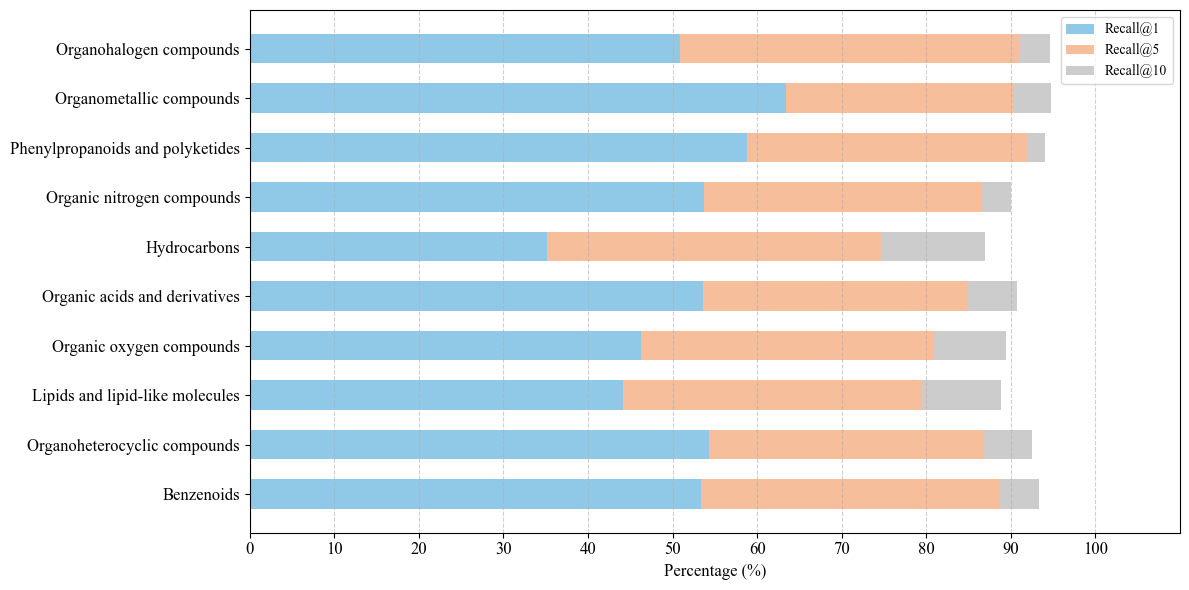

,Recall@1,Recall@5,Recall@10
Benzenoids,0.533076,0.887283,0.932884
Organoheterocyclic compounds,0.543086,0.868236,0.924850
Lipids and lipid-like molecules,0.441080,0.795417,0.888707
Organic oxygen compounds,0.463190,0.808793,0.894683
Organic acids and derivatives,0.536017,0.848517,0.907839
Hydrocarbons,0.351626,0.745935,0.869919
Organic nitrogen compounds,0.537604,0.866295,0.899721
Phenylpropanoids and polyketides,0.587459,0.920792,0.940594
Organometallic compounds,0.633663,0.904290,0.947195
Organohalogen compounds,0.508418,0.909091,0.946128


In [4]:
from matplotlib import rcParams

# 1. Setup fonts and load data
rcParams['font.family'] = 'Times New Roman'
csv_path = os.path.join(exp_dir, "plot_result_analyzer", f'test_unismiles_with_classification_{time_stamp}.csv')
df = pd.read_csv(csv_path)
# Remove rows where superclass is 'Unclassified' or NaN
df = df[df['superclass'].notna() & (df['superclass'] != 'Unclassified')]

# 2. Extract the top 10 most common superclasses
top_10_superclasses = df['superclass'].value_counts().head(10).index.tolist()

# 3. Define a function to calculate Recall@k
def calculate_recall_at_k(data, k):
    total_count = len(data)
    if total_count == 0:
        return 0  # Avoid division by zero
    correct_count = len(data[data['rank23'] <= k])
    return correct_count / total_count

# 4. Calculate Recall@1, @5, @10 for each of the top 10 superclasses
recall_results = {
    sc: [calculate_recall_at_k(df[df['superclass'] == sc], k) for k in [1, 5, 10]] 
    for sc in top_10_superclasses
}

# Convert to NumPy array for easy slicing in plots (Shape: len(top_10_superclasses) x 3)
recall_values = np.array(list(recall_results.values()))
y_indices = np.arange(len(top_10_superclasses))

# 5. Plot the stacked horizontal bar chart
plt.figure(figsize=(12, 6))
bar_width = 0.6

# Draw Recall@1
plt.barh(y_indices, recall_values[:, 0], height=bar_width, color='#90c9e7', label='Recall@1')
# Draw Recall@5 (Stacked on Recall@1)
plt.barh(y_indices, recall_values[:, 1] - recall_values[:, 0], left=recall_values[:, 0], 
         height=bar_width, color="#f6be9b", label='Recall@5')
# Draw Recall@10 (Stacked on Recall@5)
plt.barh(y_indices, recall_values[:, 2] - recall_values[:, 1], left=recall_values[:, 1], 
         height=bar_width, color='#cccccc', label='Recall@10')

# 6. Format axes and labels
plt.xlabel('Percentage (%)', fontsize=12)
plt.xlim(0, 1.1)
# Create percentage tick labels (0 to 100)
plt.xticks(np.arange(0, 1.1, 0.1), labels=[f'{int(i*100)}' for i in np.arange(0, 1.1, 0.1)], fontsize=12)
plt.yticks(y_indices, top_10_superclasses, fontsize=12)

# Add legend and grid
plt.legend(loc='best', bbox_to_anchor=(1, 1))
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

# 7. Save and show the plot
if 'save_dir' in locals() and save_dir is not None:
    save_path = os.path.join(save_dir, 'Recall_Bar_with_smiles_classification.png')
    plt.savefig(save_path, dpi=300)

plt.show()
# Convert recall_results to a DataFrame for better display
recall_df = pd.DataFrame.from_dict(
    recall_results, orient='index', 
    columns=['Recall@1', 'Recall@5', 'Recall@10'])
display(recall_df)

## 3.1 Calculating cosine similarity

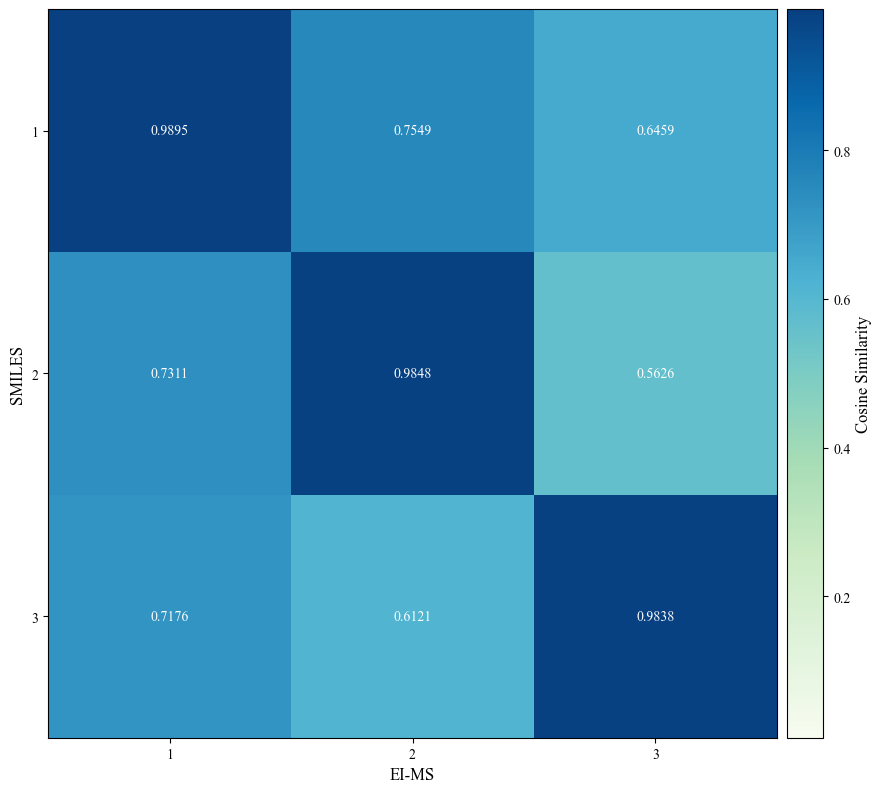

In [2]:
with open("data/External_Test_Set/xianglansu/smiles_ms.json", 'r') as f:
    datas = json.loads(f.read())
SMILES = []
EIMS = []
for data in datas:
    EIMS.append(data["peaks"])
    SMILES.append(data["smiles"])
xianglansu_data = (SMILES, EIMS) 
_, all_feature = get_data_and_features(config_path, xianglansu_data, batch_size=1)
smiles_feature, ms_feature, similarity, _, _ = all_feature

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')

norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)

for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)

ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('SMILES', fontsize=12)

if save_dir is not None:
    plt.savefig(os.path.join(save_dir, 'xianglansu_similarity.png'), dpi=300)
plt.show()

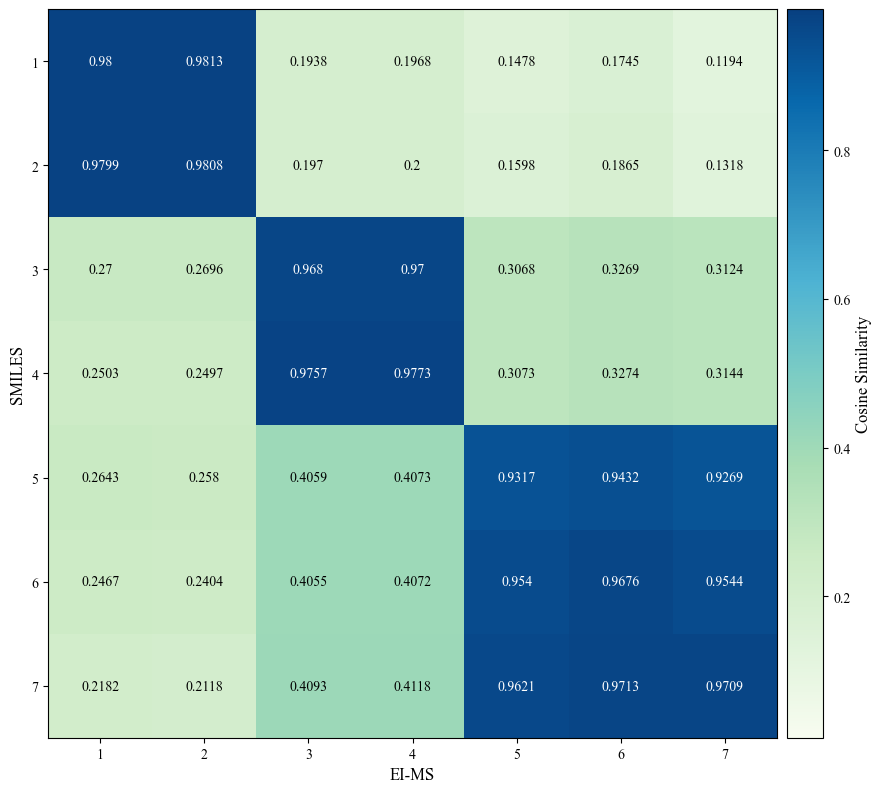

In [3]:
df = pd.read_csv("data/External_Test_Set/Iso_7/smiles_peak_data.csv")
Iso_7_data = (df["smiles"].values.tolist(), df["spectra"].values.tolist()) 
_, all_feature = get_data_and_features(config_path, Iso_7_data, batch_size=1)
smiles_feature, ms_feature, similarity, _, _ = all_feature

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')

norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)

for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)

ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('SMILES', fontsize=12)

if save_dir is not None:
    plt.savefig(os.path.join(save_dir, 'iso7_similarity.png'), dpi=300)
plt.show()

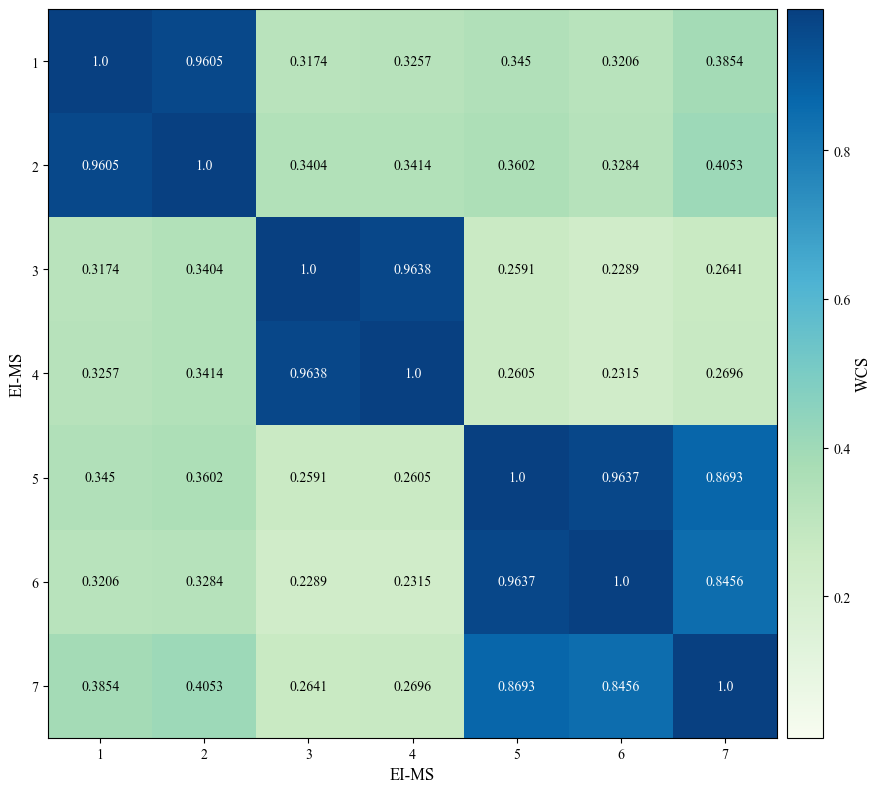

In [ ]:
wcs_ms_list = []
for ms in df["spectra"].values.tolist():
    ms_tensor = process_ms_spectra_for_wcs(ms)
    wcs_ms_list.append(ms_tensor)

wcs_ms_tensor = torch.stack(wcs_ms_list) # [7, 1000]
similarity = get_cos_distance(wcs_ms_tensor, wcs_ms_tensor)
similarity = similarity.cpu().numpy()

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')
norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)


for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)


ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('WCS', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('EI-MS', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'Recall_Comparison_Bar.png')
    plt.savefig(save_path, dpi=300)
plt.show()

# 4. Visualization and Explainability

## 4.1 Visualization of Token-Peak Interactions

In [3]:
from data_provider.dataset import get_tokenined_smiles
df = pd.read_csv("data/External_Test_Set/Gen_10/10.csv")
smile_index = 0
Gen_10_data = ([df["smiles"].values[smile_index]], [df["spectra"].values[smile_index]]) 
preprocessing_data, all_feature = get_data_and_features(config_path, Gen_10_data, batch_size=1)
smiles_ids, smiles_mask, mz, intensity, ms_mask = preprocessing_data
smiles_feature, ms_feature, similarity, smiles_score, ms_score = all_feature
print(similarity)

[[0.98193765]]


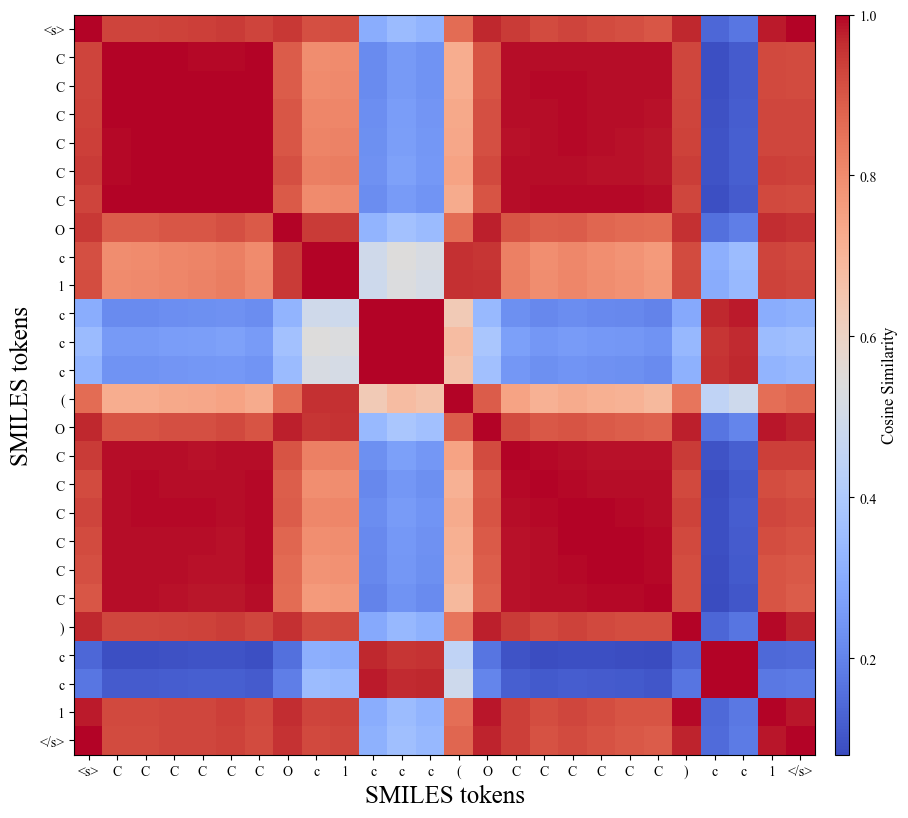

In [ ]:
#  SMILES tokens and SMILES tokens cosine similarity
smi_esa_score = smiles_score[smiles_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ smi_esa_score.cpu().numpy().T
smiles_token = get_tokenined_smiles(df["smiles"].values[smile_index], config_path)

plt.figure(figsize=(10, 10))
plt.xticks(range(len(smiles_token)), smiles_token, fontsize=10)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)
plt.xlabel('SMILES tokens', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)
ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'Recall_Comparison_Bar.png')
    plt.savefig(save_path, dpi=300)
plt.show()

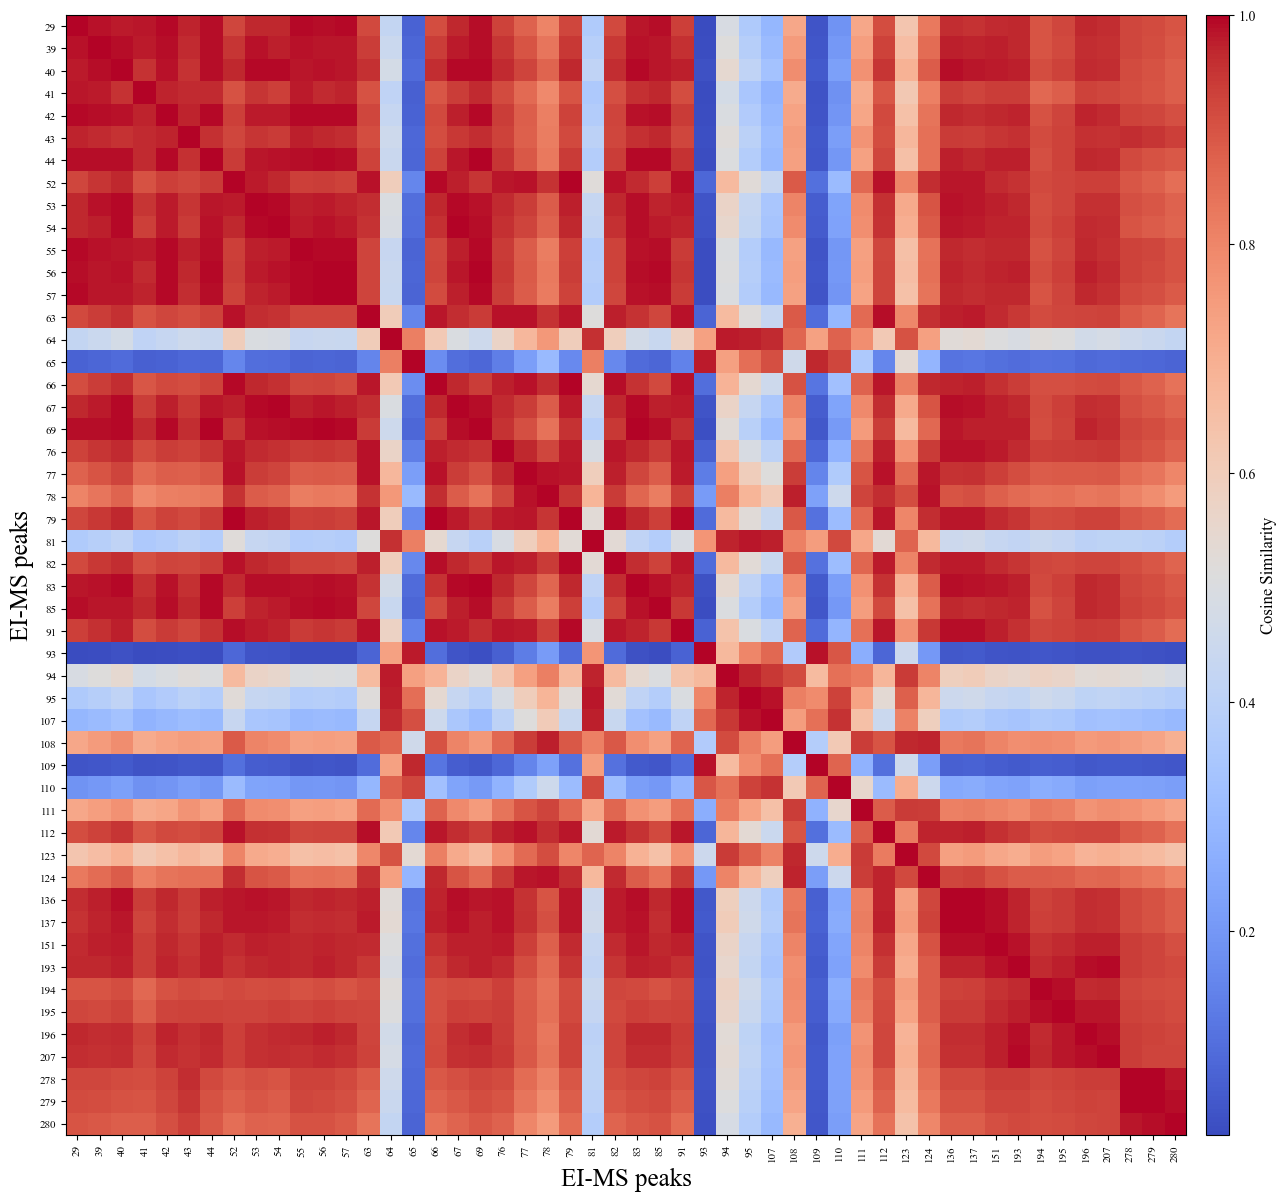

In [5]:
# EI-MS tokens and EI-MS tokens cosine similarity
mz_np = mz.squeeze(0).cpu().detach().numpy()
mask_cpu = (ms_mask.squeeze(0) == 1).cpu().numpy()
mz = mz_np[mask_cpu]
mz = mz.astype(int)

ms_esa_score = ms_score[ms_mask == 1]
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = ms_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T

plt.figure(figsize=(15, 15))
plt.xticks(range(len(mz)), mz, fontsize=8, rotation=90)
plt.yticks(range(len(mz)), mz, fontsize=8)
plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('EI-MS peaks', fontsize=18)
ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'Recall_Comparison_Bar.png')
    plt.savefig(save_path, dpi=300)
plt.show()

[[0.85938203 0.8791617  0.87755054 0.8474995  0.83835    0.8210857 ]]


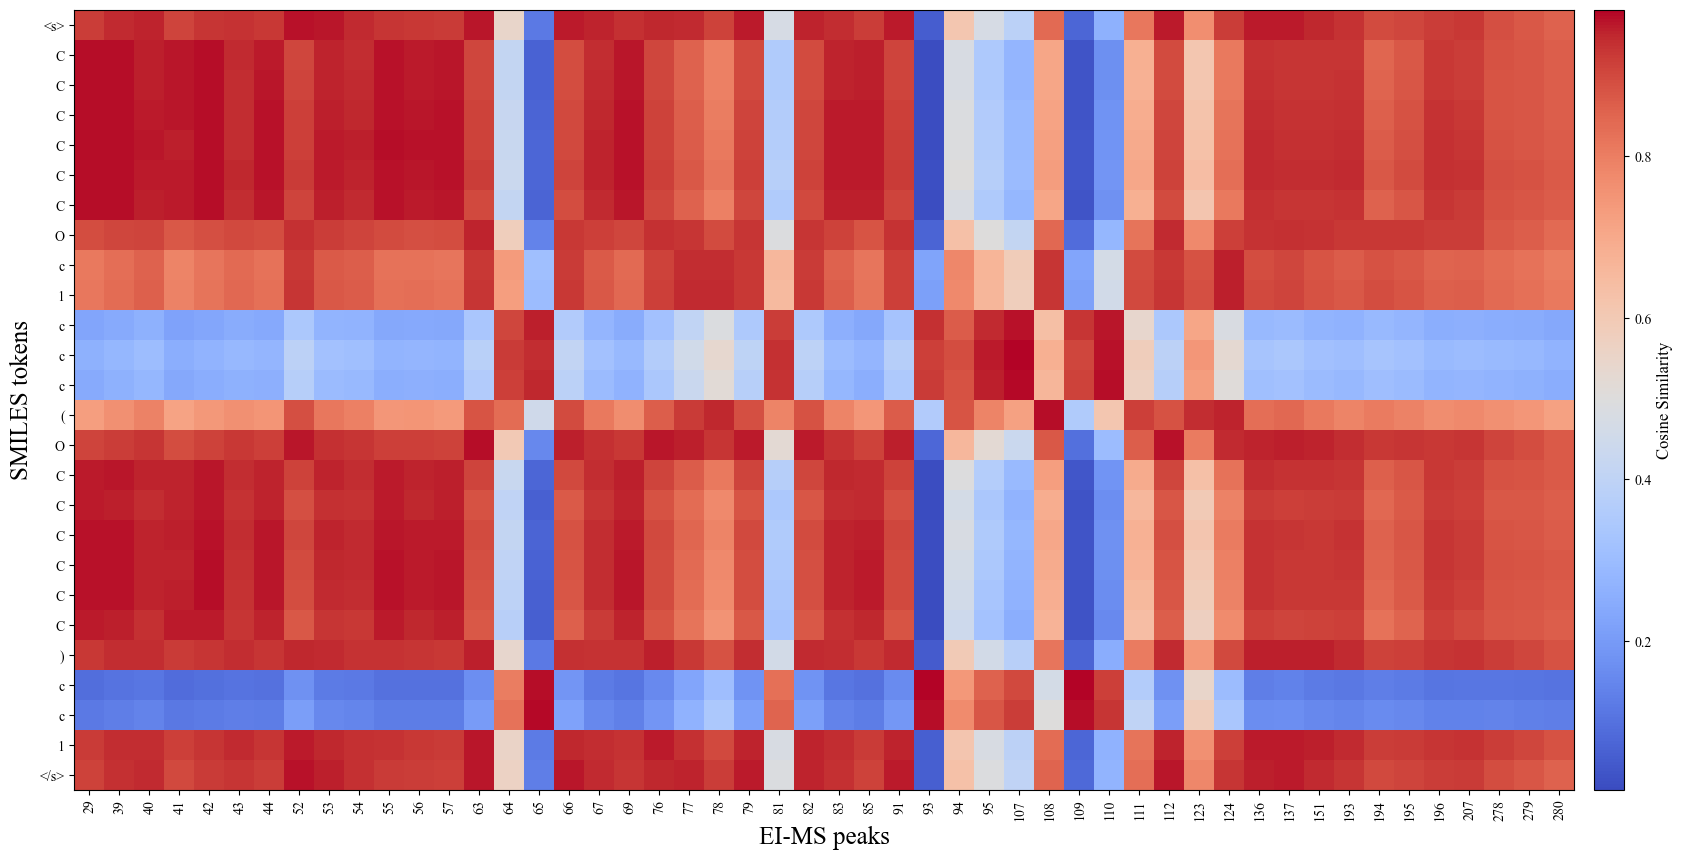

In [ ]:
# SMILES tokens and EI-MS peaks cosine similarity
smi_esa_score = smiles_score[smiles_mask == 1]
ms_esa_score = ms_score[ms_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
smiles_feature /= torch.norm(smiles_feature, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T

max_peak_molecule_similarity =  smiles_feature.cpu().numpy() @ ms_esa_score[-6:].cpu().numpy().T
print(max_peak_molecule_similarity)
plt.figure(figsize=(20, 20))
# plt.imshow(token_peak_cos_similarity, cmap='GnBu', interpolation='nearest') 
# plt.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest') 
plt.xticks(range(len(mz)), mz, fontsize=10, rotation=90)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)
# 设置坐标轴标签
plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)

ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)
if save_dir is not None:
    save_path = os.path.join(save_dir, 'Recall_Comparison_Bar.png')
    plt.savefig(save_path, dpi=300)
plt.show()

## 4.2 Cross-Modal Vector Arithmetic Verification

Searching:  32%|███▏      | 3648/11443 [00:00<00:00, 13764.48it/s]



=== Pair 43 ===
With Group (-OCH3): C=CC(CCC)OC | ID: 279610
Without Group     : C=CCCCC | ID: 422661


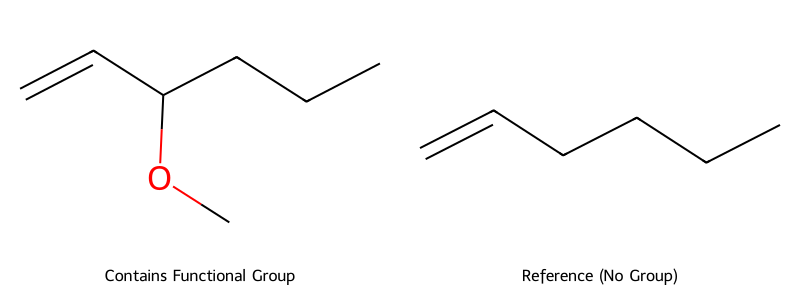


=== Pair 45 ===
With Group (-OCH3): COC1CCCCC1=O | ID: 108172
Without Group     : O=C1CCCCC1 | ID: 379487


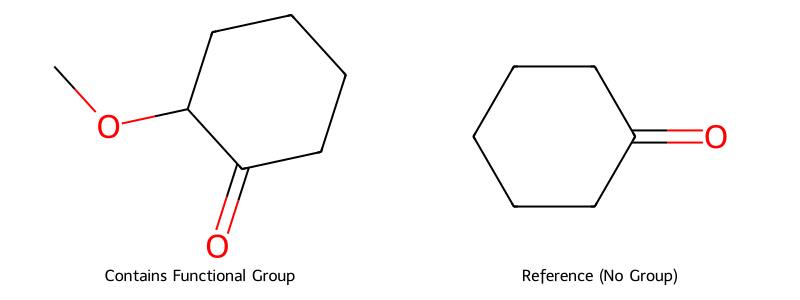


Cross-Modal Interpretability Verification
Hypothesis: Vector(With) approx Vector(Without) + Vector(Group_Delta)
Expectation: CosSim(True, Predicted) > CosSim(True, Baseline)

[Test 1: SMILES Delta -> MS Space]
Baseline Sim (MS_D vs MS_C):     0.0241
Optimized Sim (MS_D+Delta vs MS_C): 0.4388
Result: SUCCESS (Improvement: 0.4146)

[Test 2: MS Delta -> SMILES Space]
Baseline Sim (SMI_D vs SMI_C):      0.1896
Optimized Sim (SMI_D+Delta vs SMI_C): 0.4563
Result: SUCCESS (Improvement: 0.2668)


In [2]:
# ================= Execution =================
target_json = "data/nist23_data/test23/test.json"
# Example: Remove Methoxy (-OCH3) group
# Matches: [Scaffold Carbon] - [Oxygen] - [Methyl Carbon] -> [Scaffold Carbon]
transform_remove_Methoxy = '[C:1][O][C;H3]>>[C:1]' 
pairs = find_functional_group_pairs(target_json, transform_remove_Methoxy, max_pairs=50)

# ================= Configuration =================
# Indices of target molecular pairs
target_pairs_indices = [42, 44]

# Container for molecular pair data
pair_data_list = []
for idx in target_pairs_indices:
    if idx < len(pairs):
        # Extract molecules with and without the functional group
        target_pair = pairs[idx]
        mol_with = target_pair['with_group']    # Molecule A (with functional group)
        mol_without = target_pair['without_group'] # Molecule B (without functional group)
        
        # Prepare data for feature extraction: ([SMILES_A, SMILES_B], [EIMS_A, EIMS_B])
        current_smiles = [mol_with['smiles'], mol_without['smiles']]
        current_spectra = [mol_with['peaks'], mol_without['peaks']]
        
        pair_data_list.append({
            "idx": idx,
            "data": (current_smiles, current_spectra),
            "info": (mol_with, mol_without)
        })
        print(f"\n=== Pair {idx+1} ===")
        # Use .get() to avoid KeyError if 'nist' id is missing
        print(f"With Group (-OCH3): {mol_with['smiles']} | ID: {mol_with.get('nist', 'N/A')}")
        print(f"Without Group     : {mol_without['smiles']} | ID: {mol_without.get('nist', 'N/A')}")
        # Visualize molecular structures
        mols = [Chem.MolFromSmiles(mol_with['smiles']), Chem.MolFromSmiles(mol_without['smiles'])]
        img = Draw.MolsToGridImage(mols, molsPerRow=2, subImgSize=(400, 300), 
                                   legends=["Contains Functional Group", "Reference (No Group)"])
        display(img)
    else:
        print(f"  [Warning] Pair index {idx} out of range (Total pairs: {len(pairs)})")

if len(pair_data_list) < 2:
    print("Error: Not enough pairs loaded for calculation.")
else:
    # ----------------------------------------------------------------------------------
    # Step 1: Extract feature vectors
    # ----------------------------------------------------------------------------------
    # First pair (A, B) -> Used to calculate the delta vector
    _, all_features_AB = get_data_and_features(config_path, pair_data_list[0]['data'], batch_size=2)
    smi_feat_AB, ms_feat_AB, _, _, _ = all_features_AB
    smi_feat_AB = smi_feat_AB.cpu().numpy()
    ms_feat_AB = ms_feat_AB.cpu().numpy()
    
    mol_A, mol_B = smi_feat_AB[0], smi_feat_AB[1] # A: With, B: Without
    ms_A, ms_B = ms_feat_AB[0], ms_feat_AB[1]

    # Second pair (C, D) -> Used for validation
    _, all_features_CD = get_data_and_features(config_path, pair_data_list[1]['data'], batch_size=2)
    smi_feat_CD, ms_feat_CD, _, _, _ = all_features_CD
    smi_feat_CD = smi_feat_CD.cpu().numpy()
    ms_feat_CD = ms_feat_CD.cpu().numpy()
    
    mol_C, mol_D = smi_feat_CD[0], smi_feat_CD[1] # C: With, D: Without
    ms_C, ms_D = ms_feat_CD[0], ms_feat_CD[1]

    print("\n" + "="*50)
    print("Cross-Modal Interpretability Verification")
    print("Hypothesis: Vector(With) approx Vector(Without) + Vector(Group_Delta)")
    print("Expectation: CosSim(True, Predicted) > CosSim(True, Baseline)")
    print("="*50)

    # ----------------------------------------------------------------------------------
    # Test 1: Predict mass spectrum changes from molecular delta
    # Logic: MS_Predicted = MS_Without + (SMILES_With - SMILES_Without)
    # ----------------------------------------------------------------------------------
    delta_smi_AB = mol_A - mol_B  # Delta vector in SMILES space
    
    # Cross-modal addition: Baseline MS + Functional group SMILES
    ms_C_predicted = ms_D + delta_smi_AB 
    
    # Normalize vectors
    norm_ms_C = ms_C / np.linalg.norm(ms_C)            # Ground truth (Target)
    norm_ms_D = ms_D / np.linalg.norm(ms_D)            # Baseline
    norm_ms_C_pred = ms_C_predicted / np.linalg.norm(ms_C_predicted) # Prediction
    
    # Calculate cosine similarity
    sim_ms_baseline = np.dot(norm_ms_C, norm_ms_D)      # Similarity between D and C
    sim_ms_optimized = np.dot(norm_ms_C, norm_ms_C_pred) # Similarity between predicted C' and C
    
    print("\n[Test 1: SMILES Delta -> MS Space]")
    print(f"Baseline Sim (MS_D vs MS_C):     {sim_ms_baseline:.4f}")
    print(f"Optimized Sim (MS_D+Delta vs MS_C): {sim_ms_optimized:.4f}")
    print(f"Result: {'SUCCESS' if sim_ms_optimized > sim_ms_baseline else 'FAIL'} (Improvement: {sim_ms_optimized - sim_ms_baseline:.4f})")

    # ----------------------------------------------------------------------------------
    # Test 2: Predict molecular changes from mass spectrum delta
    # Logic: SMILES_Predicted = SMILES_Without + (MS_With - MS_Without)
    # ----------------------------------------------------------------------------------
    delta_ms_AB = ms_A - ms_B     # Delta vector in MS space
    
    # Cross-modal addition: Baseline SMILES + Functional group MS
    mol_C_predicted = mol_D + delta_ms_AB
    
    # Normalize vectors
    norm_mol_C = mol_C / np.linalg.norm(mol_C)
    norm_mol_D = mol_D / np.linalg.norm(mol_D)
    norm_mol_C_pred = mol_C_predicted / np.linalg.norm(mol_C_predicted)
    
    # Calculate cosine similarity
    sim_mol_baseline = np.dot(norm_mol_C, norm_mol_D)
    sim_mol_optimized = np.dot(norm_mol_C, norm_mol_C_pred)
    
    print("\n[Test 2: MS Delta -> SMILES Space]")
    print(f"Baseline Sim (SMI_D vs SMI_C):      {sim_mol_baseline:.4f}")
    print(f"Optimized Sim (SMI_D+Delta vs SMI_C): {sim_mol_optimized:.4f}")
    print(f"Result: {'SUCCESS' if sim_mol_optimized > sim_mol_baseline else 'FAIL'} (Improvement: {sim_mol_optimized - sim_mol_baseline:.4f})")

Loading dataset from data/nist23_data/test23/test.json...

=== Pair 1: 108258 vs 557882 ===
With Group  : CCOCCCl | ID: 108258
Without Group: CCOCC | ID: 557882


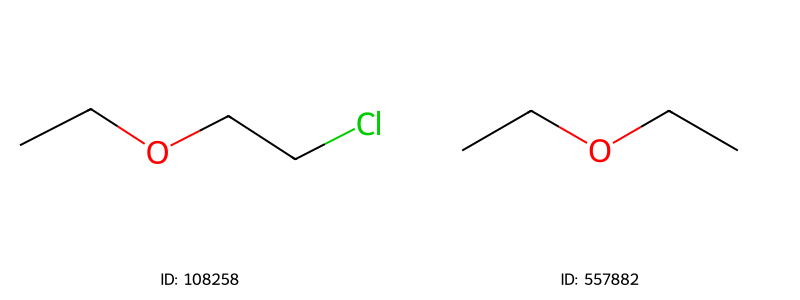


=== Pair 2: 61425 vs 429717 ===
With Group  : CCOC(CCl)OCC | ID: 61425
Without Group: CCOC(C)OCC | ID: 429717


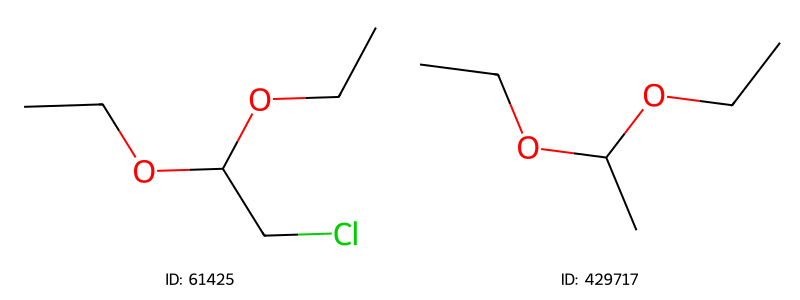


Cross-Modal Interpretability Verification
Hypothesis: Vector(With) approx Vector(Without) + Vector(Group_Delta)
Expectation: CosSim(True, Predicted) > CosSim(True, Baseline)

[Test 1: SMILES Delta -> MS Space]
Baseline Sim (MS_D vs MS_C):     0.4359
Optimized Sim (MS_D+Delta vs MS_C): 0.7297
Result: SUCCESS (Improvement: 0.2939)

[Test 2: MS Delta -> SMILES Space]
Baseline Sim (SMI_D vs SMI_C):      0.2629
Optimized Sim (SMI_D+Delta vs SMI_C): 0.6381
Result: SUCCESS (Improvement: 0.3753)


In [3]:
# ================= Configuration =================
target_pair_ids = [("108258", "557882"), ("61425", "429717")]
target_json = "data/nist23_data/test23/test.json"

# ================= Data Loading & Processing =================
print(f"Loading dataset from {target_json}...")
with open(target_json, 'r') as f:
    data_list = json.load(f)

# Build ID map
id_map = {str(item.get('nist_id', item.get('id', item.get('nist', '')))): item for item in data_list}

pair_data_list = []
for i, (id_a, id_b) in enumerate(target_pair_ids):
    mol_a, mol_b = id_map[str(id_a)], id_map[str(id_b)]
    print(f"\n=== Pair {i+1}: {id_a} vs {id_b} ===")
    print(f"With Group  : {mol_a['smiles']} | ID: {id_a}")
    print(f"Without Group: {mol_b['smiles']} | ID: {id_b}")
    
    # Store data for analysis
    pair_data_list.append({
        "data": ([mol_a['smiles'], mol_b['smiles']], [mol_a['peaks'], mol_b['peaks']]),
        "info": (mol_a, mol_b)
    })
    
    # Visualize
    img = Draw.MolsToGridImage(
        [Chem.MolFromSmiles(mol_a['smiles']), Chem.MolFromSmiles(mol_b['smiles'])], 
        molsPerRow=2, subImgSize=(400, 300), 
        legends=[f"ID: {id_a}", f"ID: {id_b}"], useSVG=False
    )
    display(img)

if len(pair_data_list) < 2:
    print("Error: Not enough pairs loaded for calculation.")
else:
    # ----------------------------------------------------------------------------------
    # Step 1: Extract feature vectors
    # ----------------------------------------------------------------------------------
    # First pair (A, B) -> Used to calculate the delta vector
    _, all_features_AB = get_data_and_features(config_path, pair_data_list[0]['data'], batch_size=2)
    smi_feat_AB, ms_feat_AB, _, _, _ = all_features_AB
    smi_feat_AB = smi_feat_AB.cpu().numpy()
    ms_feat_AB = ms_feat_AB.cpu().numpy()
    
    mol_A, mol_B = smi_feat_AB[0], smi_feat_AB[1] # A: With, B: Without
    ms_A, ms_B = ms_feat_AB[0], ms_feat_AB[1]

    # Second pair (C, D) -> Used for validation
    _, all_features_CD = get_data_and_features(config_path, pair_data_list[1]['data'], batch_size=2)
    smi_feat_CD, ms_feat_CD, _, _, _ = all_features_CD
    smi_feat_CD = smi_feat_CD.cpu().numpy()
    ms_feat_CD = ms_feat_CD.cpu().numpy()
    
    mol_C, mol_D = smi_feat_CD[0], smi_feat_CD[1] # C: With, D: Without
    ms_C, ms_D = ms_feat_CD[0], ms_feat_CD[1]

    print("\n" + "="*50)
    print("Cross-Modal Interpretability Verification")
    print("Hypothesis: Vector(With) approx Vector(Without) + Vector(Group_Delta)")
    print("Expectation: CosSim(True, Predicted) > CosSim(True, Baseline)")
    print("="*50)

    # ----------------------------------------------------------------------------------
    # Test 1: Predict mass spectrum changes from molecular delta
    # Logic: MS_Predicted = MS_Without + (SMILES_With - SMILES_Without)
    # ----------------------------------------------------------------------------------
    delta_smi_AB = mol_A - mol_B  # Delta vector in SMILES space
    
    # Cross-modal addition: Baseline MS + Functional group SMILES
    ms_C_predicted = ms_D + delta_smi_AB 
    
    # Normalize vectors
    norm_ms_C = ms_C / np.linalg.norm(ms_C)            # Ground truth (Target)
    norm_ms_D = ms_D / np.linalg.norm(ms_D)            # Baseline
    norm_ms_C_pred = ms_C_predicted / np.linalg.norm(ms_C_predicted) # Prediction
    
    # Calculate cosine similarity
    sim_ms_baseline = np.dot(norm_ms_C, norm_ms_D)      # Similarity between D and C
    sim_ms_optimized = np.dot(norm_ms_C, norm_ms_C_pred) # Similarity between predicted C' and C
    
    print("\n[Test 1: SMILES Delta -> MS Space]")
    print(f"Baseline Sim (MS_D vs MS_C):     {sim_ms_baseline:.4f}")
    print(f"Optimized Sim (MS_D+Delta vs MS_C): {sim_ms_optimized:.4f}")
    print(f"Result: {'SUCCESS' if sim_ms_optimized > sim_ms_baseline else 'FAIL'} (Improvement: {sim_ms_optimized - sim_ms_baseline:.4f})")

    # ----------------------------------------------------------------------------------
    # Test 2: Predict molecular changes from mass spectrum delta
    # Logic: SMILES_Predicted = SMILES_Without + (MS_With - MS_Without)
    # ----------------------------------------------------------------------------------
    delta_ms_AB = ms_A - ms_B     # Delta vector in MS space
    
    # Cross-modal addition: Baseline SMILES + Functional group MS
    mol_C_predicted = mol_D + delta_ms_AB
    
    # Normalize vectors
    norm_mol_C = mol_C / np.linalg.norm(mol_C)
    norm_mol_D = mol_D / np.linalg.norm(mol_D)
    norm_mol_C_pred = mol_C_predicted / np.linalg.norm(mol_C_predicted)
    
    # Calculate cosine similarity
    sim_mol_baseline = np.dot(norm_mol_C, norm_mol_D)
    sim_mol_optimized = np.dot(norm_mol_C, norm_mol_C_pred)
    
    print("\n[Test 2: MS Delta -> SMILES Space]")
    print(f"Baseline Sim (SMI_D vs SMI_C):      {sim_mol_baseline:.4f}")
    print(f"Optimized Sim (SMI_D+Delta vs SMI_C): {sim_mol_optimized:.4f}")
    print(f"Result: {'SUCCESS' if sim_mol_optimized > sim_mol_baseline else 'FAIL'} (Improvement: {sim_mol_optimized - sim_mol_baseline:.4f})")

Loading dataset from data/nist23_data/test23/test.json...

=== Pair 1: 544504 vs 544502 ===
With Group  : COC(=O)CC(C)CCC=C(C)C | ID: 544504
Without Group: CC(C)=CCCC(C)CC(=O)O | ID: 544502


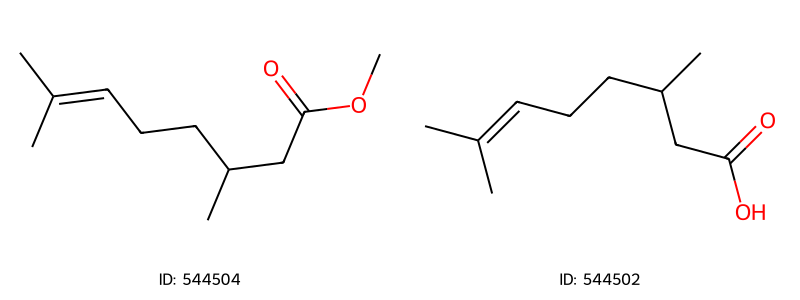


=== Pair 2: 194235 vs 1309 ===
With Group  : COC(=O)CC(C)O | ID: 194235
Without Group: CC(O)CC(=O)O | ID: 1309


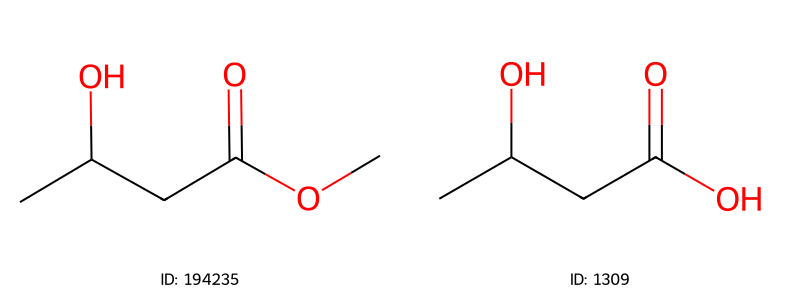


Cross-Modal Interpretability Verification
Hypothesis: Vector(With) approx Vector(Without) + Vector(Group_Delta)
Expectation: CosSim(True, Predicted) > CosSim(True, Baseline)

[Test 1: SMILES Delta -> MS Space]
Baseline Sim (MS_D vs MS_C):     0.5690
Optimized Sim (MS_D+Delta vs MS_C): 0.6184
Result: SUCCESS (Improvement: 0.0494)

[Test 2: MS Delta -> SMILES Space]
Baseline Sim (SMI_D vs SMI_C):      0.6059
Optimized Sim (SMI_D+Delta vs SMI_C): 0.6315
Result: SUCCESS (Improvement: 0.0256)


In [5]:
# ================= Configuration =================
target_pair_ids = [("544504", "544502"),  ("194235", "1309"),
                #    ("429178", "230359"), 
                   ]
target_json = "data/nist23_data/test23/test.json"

# ================= Data Loading & Processing =================
print(f"Loading dataset from {target_json}...")
with open(target_json, 'r') as f:
    data_list = json.load(f)

# Build ID map
id_map = {str(item.get('nist_id', item.get('id', item.get('nist', '')))): item for item in data_list}

pair_data_list = []
for i, (id_a, id_b) in enumerate(target_pair_ids):
    mol_a, mol_b = id_map[str(id_a)], id_map[str(id_b)]
    print(f"\n=== Pair {i+1}: {id_a} vs {id_b} ===")
    print(f"With Group  : {mol_a['smiles']} | ID: {id_a}")
    print(f"Without Group: {mol_b['smiles']} | ID: {id_b}")
    
    # Store data for analysis
    pair_data_list.append({
        "data": ([mol_a['smiles'], mol_b['smiles']], [mol_a['peaks'], mol_b['peaks']]),
        "info": (mol_a, mol_b)
    })
    
    # Visualize
    img = Draw.MolsToGridImage(
        [Chem.MolFromSmiles(mol_a['smiles']), Chem.MolFromSmiles(mol_b['smiles'])], 
        molsPerRow=2, subImgSize=(400, 300), 
        legends=[f"ID: {id_a}", f"ID: {id_b}"], useSVG=False
    )
    display(img)

if len(pair_data_list) < 2:
    print("Error: Not enough pairs loaded for calculation.")
else:
    # ----------------------------------------------------------------------------------
    # Step 1: Extract feature vectors
    # ----------------------------------------------------------------------------------
    # First pair (A, B) -> Used to calculate the delta vector
    _, all_features_AB = get_data_and_features(config_path, pair_data_list[0]['data'], batch_size=2)
    smi_feat_AB, ms_feat_AB, _, _, _ = all_features_AB
    smi_feat_AB = smi_feat_AB.cpu().numpy()
    ms_feat_AB = ms_feat_AB.cpu().numpy()
    
    mol_A, mol_B = smi_feat_AB[0], smi_feat_AB[1] # A: With, B: Without
    ms_A, ms_B = ms_feat_AB[0], ms_feat_AB[1]

    # Second pair (C, D) -> Used for validation
    _, all_features_CD = get_data_and_features(config_path, pair_data_list[1]['data'], batch_size=2)
    smi_feat_CD, ms_feat_CD, _, _, _ = all_features_CD
    smi_feat_CD = smi_feat_CD.cpu().numpy()
    ms_feat_CD = ms_feat_CD.cpu().numpy()
    
    mol_C, mol_D = smi_feat_CD[0], smi_feat_CD[1] # C: With, D: Without
    ms_C, ms_D = ms_feat_CD[0], ms_feat_CD[1]

    print("\n" + "="*50)
    print("Cross-Modal Interpretability Verification")
    print("Hypothesis: Vector(With) approx Vector(Without) + Vector(Group_Delta)")
    print("Expectation: CosSim(True, Predicted) > CosSim(True, Baseline)")
    print("="*50)

    # ----------------------------------------------------------------------------------
    # Test 1: Predict mass spectrum changes from molecular delta
    # Logic: MS_Predicted = MS_Without + (SMILES_With - SMILES_Without)
    # ----------------------------------------------------------------------------------
    delta_smi_AB = mol_A - mol_B  # Delta vector in SMILES space
    
    # Cross-modal addition: Baseline MS + Functional group SMILES
    ms_C_predicted = ms_D + delta_smi_AB 
    
    # Normalize vectors
    norm_ms_C = ms_C / np.linalg.norm(ms_C)            # Ground truth (Target)
    norm_ms_D = ms_D / np.linalg.norm(ms_D)            # Baseline
    norm_ms_C_pred = ms_C_predicted / np.linalg.norm(ms_C_predicted) # Prediction
    
    # Calculate cosine similarity
    sim_ms_baseline = np.dot(norm_ms_C, norm_ms_D)      # Similarity between D and C
    sim_ms_optimized = np.dot(norm_ms_C, norm_ms_C_pred) # Similarity between predicted C' and C
    
    print("\n[Test 1: SMILES Delta -> MS Space]")
    print(f"Baseline Sim (MS_D vs MS_C):     {sim_ms_baseline:.4f}")
    print(f"Optimized Sim (MS_D+Delta vs MS_C): {sim_ms_optimized:.4f}")
    print(f"Result: {'SUCCESS' if sim_ms_optimized > sim_ms_baseline else 'FAIL'} (Improvement: {sim_ms_optimized - sim_ms_baseline:.4f})")

    # ----------------------------------------------------------------------------------
    # Test 2: Predict molecular changes from mass spectrum delta
    # Logic: SMILES_Predicted = SMILES_Without + (MS_With - MS_Without)
    # ----------------------------------------------------------------------------------
    delta_ms_AB = ms_A - ms_B     # Delta vector in MS space
    
    # Cross-modal addition: Baseline SMILES + Functional group MS
    mol_C_predicted = mol_D + delta_ms_AB
    
    # Normalize vectors
    norm_mol_C = mol_C / np.linalg.norm(mol_C)
    norm_mol_D = mol_D / np.linalg.norm(mol_D)
    norm_mol_C_pred = mol_C_predicted / np.linalg.norm(mol_C_predicted)
    
    # Calculate cosine similarity
    sim_mol_baseline = np.dot(norm_mol_C, norm_mol_D)
    sim_mol_optimized = np.dot(norm_mol_C, norm_mol_C_pred)
    
    print("\n[Test 2: MS Delta -> SMILES Space]")
    print(f"Baseline Sim (SMI_D vs SMI_C):      {sim_mol_baseline:.4f}")
    print(f"Optimized Sim (SMI_D+Delta vs SMI_C): {sim_mol_optimized:.4f}")
    print(f"Result: {'SUCCESS' if sim_mol_optimized > sim_mol_baseline else 'FAIL'} (Improvement: {sim_mol_optimized - sim_mol_baseline:.4f})")

In [33]:
target_json = "data/nist23_data/test23/test.json"
target_ids = ["279610", "422661", "108172", "379487",
              "108258", "557882", "61425", "429717"]  # Example IDs to check

print(f"Checking for IDs {target_ids} in {target_json}...")

if os.path.exists(target_json):
    with open(target_json, 'r') as f:
        data_list = json.load(f)
    
    found_count = 0
    # Create a lookup dictionary for faster access if needed, or just iterate
    # Assuming 'nist' is the key based on previous context
    
    print("-" * 40)
    for target_id in target_ids:
        found = False
        for item in data_list:
            # Check both string and int representation just in case
            if str(item.get('nist_id', '')) == target_id or str(item.get('id', '')) == target_id or str(item.get('nist', '')) == target_id:
                print(f"[FOUND] ID: {target_id}")
                print(f"  SMILES: {item.get('smiles')}")
                print(f"  Data: {item.keys()}")
                found = True
                found_count += 1
                break
        if not found:
            print(f"[MISSING] ID: {target_id} not found in dataset.")
    print("-" * 40)
    print(f"Total found: {found_count} / {len(target_ids)}")

else:
    print(f"Error: File {target_json} not found.")

Checking for IDs ['279610', '422661', '108172', '379487', '108258', '557882', '61425', '429717'] in data/nist23_data/test23/test.json...
----------------------------------------
[FOUND] ID: 279610
  SMILES: C=CC(CCC)OC
  Data: dict_keys(['name', 'InChIKey', 'formula', 'molecular_weight', 'exact_mass', 'nist', 'db', 'num_peaks', 'peaks', 'smiles'])
[FOUND] ID: 422661
  SMILES: C=CCCCC
  Data: dict_keys(['name', 'InChIKey', 'formula', 'molecular_weight', 'exact_mass', 'nist', 'db', 'num_peaks', 'peaks', 'smiles'])
[FOUND] ID: 108172
  SMILES: COC1CCCCC1=O
  Data: dict_keys(['name', 'InChIKey', 'formula', 'molecular_weight', 'exact_mass', 'nist', 'db', 'num_peaks', 'peaks', 'smiles'])
[FOUND] ID: 379487
  SMILES: O=C1CCCCC1
  Data: dict_keys(['name', 'InChIKey', 'formula', 'molecular_weight', 'exact_mass', 'nist', 'db', 'num_peaks', 'peaks', 'smiles'])
[FOUND] ID: 108258
  SMILES: CCOCCCl
  Data: dict_keys(['name', 'InChIKey', 'formula', 'molecular_weight', 'exact_mass', 'nist', 'db', 'nu

# 5. Molecular localization in GC-MS files

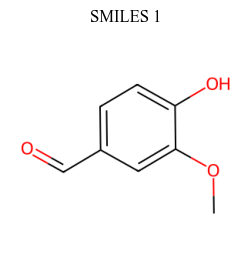

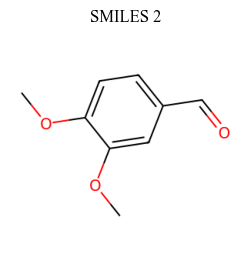

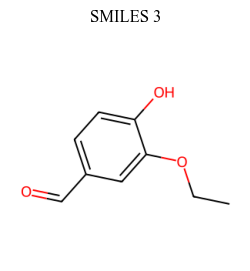

In [14]:
from utils.NetCDF import data_load, netcdf_reader
filename = 'data/External_Test_Set/xianglansu/250106-奶粉-香兰素.CDF'
X, mz, rt = data_load(filename)
num_ms, num_mz = X.shape
mz = np.tile(mz, (num_ms, 1))
set1_mass_data = np.dstack((mz, X))

with open("data/External_Test_Set/xianglansu/smiles_ms.json", 'r') as f:
    datas = json.loads(f.read())
smiles_list = []
nist_ms_list = []
for data in datas:
    nist_ms_list.append(data["peaks"])
    smiles_list.append(data["smiles"])

# === GC-MS Data Preprocessing: Mass Filtering ===
# Purpose: Filter out high m/z fragments that exceed the target molecular weight (e.g., Vanillin MW ~152.15).
# Why we do this: These larger fragments typically originate from background noise, column bleed, or sample matrix interference. 
# Removing them effectively reduces false signals, improving the accuracy of downstream spectral matching and model retrieval.
MAX_MZ_THRESHOLD = 152.15 
# Simplify logic using NumPy boolean masking: efficiently keep only m/z <= threshold for each scan
filtered_set1_data = [scan[scan[:, 0] <= MAX_MZ_THRESHOLD].tolist() for scan in set1_mass_data]

plot_mol_structure(smiles_list)

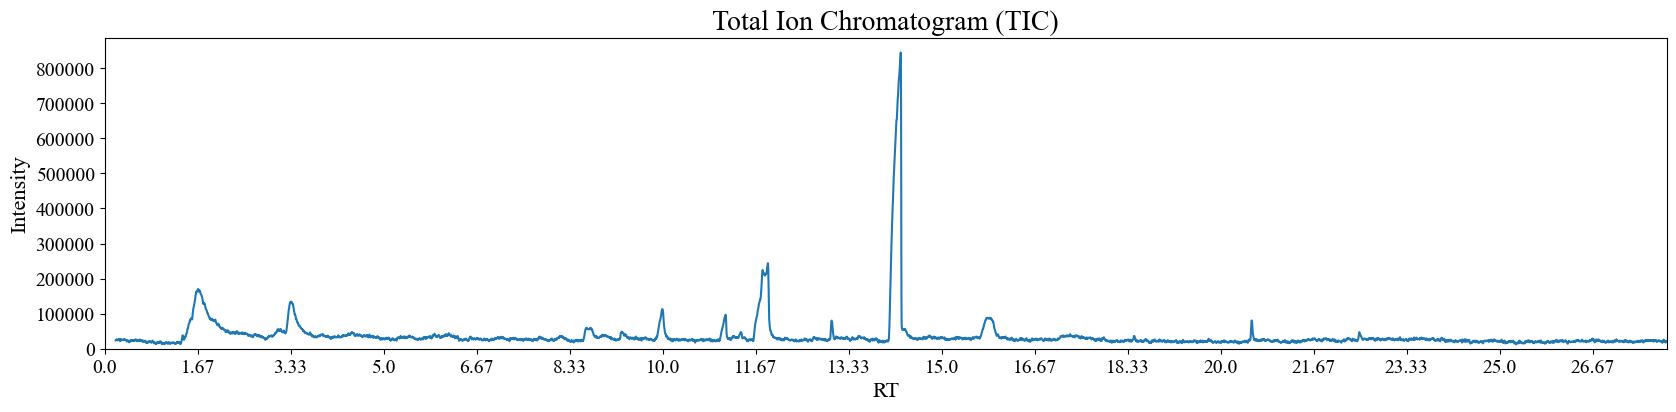

In [24]:
from matplotlib.ticker import MultipleLocator

ncr = netcdf_reader(filename, bmmap=True)
tic_data = ncr.tic()
rt_full = tic_data['rt']
int_full = tic_data['intensity']

# 去除溶剂峰
rt_cut = 0.2
mask = rt_full >= rt_cut
rt_filtered = rt_full[mask]
int_filtered = int_full[mask]

fig, ax = plt.subplots(figsize=(20, 4))
ax.plot(rt_filtered, int_filtered)

# Y轴关闭科学计数，刻度间隔300000
ax.get_yaxis().get_major_formatter().set_scientific(False)
y_major_locator = MultipleLocator(100000)
ax.yaxis.set_major_locator(y_major_locator)

ax.set_xlabel('RT', fontsize=16)
ax.set_ylabel('Intensity', fontsize=16)
ax.set_title('Total Ion Chromatogram (TIC)', fontsize=20)

# X轴范围，从0紧贴Y轴，右端和热力图一致
ax.set_xlim(left=0, right=rt_full.max())
ax.set_ylim(bottom=0)

# X刻度和热力图保持完全一致
tick_pos_idx = np.arange(0, len(rt), step=500)
ax.set_xticks(ticks=rt[tick_pos_idx])
ax.set_xticklabels(labels=np.round(rt[tick_pos_idx], 2), fontsize=14)
ax.tick_params(axis='y', labelsize=14)

ax.set_position([0.0625, 0.1366, 0.7812, 0.7768])

plt.show()

## 5.1 EI-MS WCS match

[0.9739492  0.38748905 0.4971105 ]
14.1167(0.9739)
16.5333(0.3875)
20.8900(0.4971)

==== Heatmap Ax Bounding Box ====
x0(left): 0.0625, y0(bottom): 0.1366
x1(right): 0.8437, y1(top): 0.9133
width = 0.7812, height = 0.7768


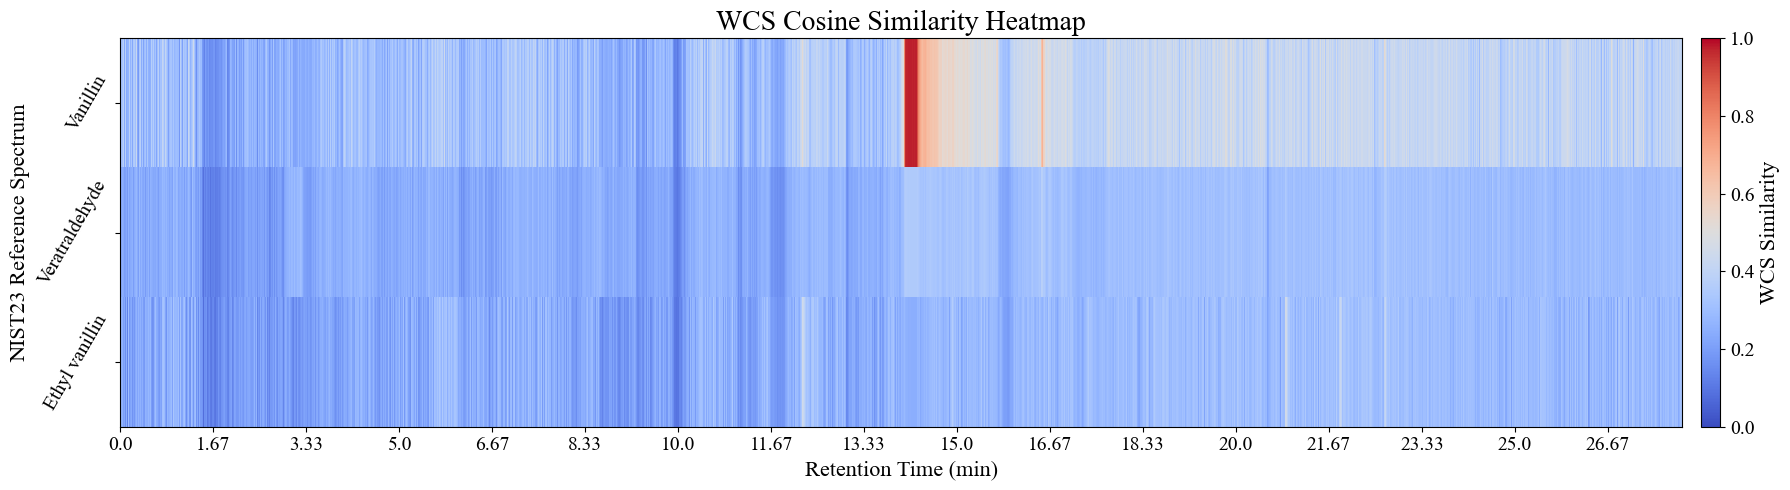

In [21]:
nist_ms_tensor = torch.cat([process_ms_spectra_for_wcs(nist_ms, 1000) for nist_ms in nist_ms_list], dim=0).reshape(-1, 1000)
# set1_ms_tensor = torch.cat([process_ms_spectra_for_wcs(set1_ms, 1000) for set1_ms in set1_mass_data], dim=0).reshape(-1, 1000)
set1_ms_tensor = torch.cat([process_ms_spectra_for_wcs(set1_ms, 1000) for set1_ms in filtered_set1_data], dim=0).reshape(-1, 1000)
nist_ms_tensor /= torch.norm(nist_ms_tensor, dim=-1, keepdim=True)
set1_ms_tensor /= torch.norm(set1_ms_tensor, dim=-1, keepdim=True)
wcs_similarity = nist_ms_tensor @ set1_ms_tensor.T
wcs_similarity[torch.isnan(wcs_similarity)] = 0
wcs_similarity = wcs_similarity.cpu().numpy()
# Print the maximum value of each row, the column index of the maximum value, and retrieve the corresponding RT
max_distance = wcs_similarity.max(axis=1)
print(max_distance)
rt_list = rt[wcs_similarity.argmax(axis=1).tolist()]
result = np.concatenate([np.round(rt_list, 4).reshape(-1, 1), np.round(max_distance, 4).reshape(-1, 1)], axis=1)
for i in range(len(result)):
    print(f"{result[i][0]:.4f}({result[i][1]:.4f})")

# Plot heatmap
name = ['Vanillin', 'Veratraldehyde', 'Ethyl vanillin']
plt.figure(figsize=(20, 5))
# im = plt.imshow(wcs_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=np.percentile(wcs_similarity, 95), vmax=wcs_similarity.max()))
im = plt.imshow(wcs_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=0, vmax=1))

cbar = plt.colorbar(im, pad=0.01)
cbar.set_label('WCS Similarity', size=16)
cbar.ax.tick_params(labelsize=14) 

plt.title('WCS Cosine Similarity Heatmap', fontsize=20)
plt.xlabel('Retention Time (min)', fontsize=16)
plt.ylabel('NIST23 Reference Spectrum', fontsize=16)

plt.xticks(
    ticks=np.arange(0, len(rt), step=500), 
    labels=np.round(rt[np.arange(0, len(rt), step=500)], 2),
    fontsize=14
)

plt.yticks(
    ticks=np.arange(0, len(nist_ms_list), step=1), 
    labels=name, 
    rotation=60,  
    va='center',   
    fontsize=14   
)

plt.tight_layout()

ax = plt.gca()
bbox = ax.get_position()
print("\n==== Heatmap Ax Bounding Box ====")
print(f"x0(left): {bbox.x0:.4f}, y0(bottom): {bbox.y0:.4f}")
print(f"x1(right): {bbox.x1:.4f}, y1(top): {bbox.y1:.4f}")
print(f"width = {bbox.x1 - bbox.x0:.4f}, height = {bbox.y1 - bbox.y0:.4f}")

plt.show()
# plt.savefig("fig/location/wcs_similarity_heatmap.png", bbox_inches='tight')
plt.show()

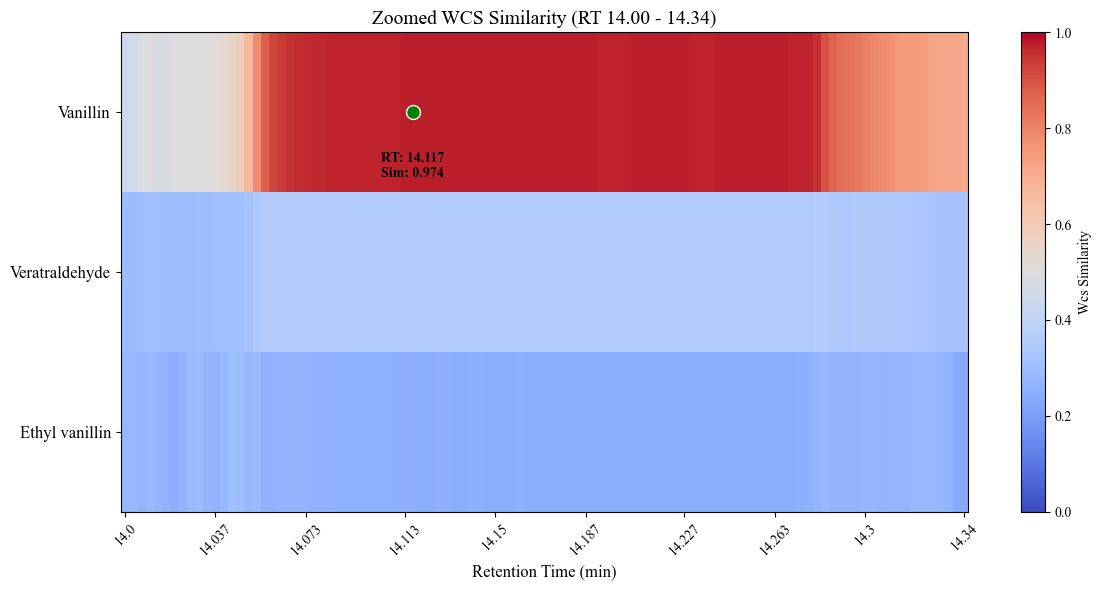

In [ ]:
# 1. Automatically determine zoom range: extend 0.15 min before and after the RT of the best matching point
# zoom_start, zoom_end = 14.050, 14.285
zoom_start, zoom_end =  14.00, 14.34
mask = (rt >= zoom_start) & (rt <= zoom_end)

if not mask.any():
    print(f"Warning: No data found in range RT {zoom_start}-{zoom_end}")
else:
    # 2. Prepare sliced data
    sub_sim = wcs_similarity[:, mask]
    sub_rt = rt[mask]
    start_global_idx = np.where(mask)[0][0]  # Starting global index corresponding to the current slice

    # 3. Plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Draw heatmap
    # Keep consistent colormap with full-view plot; aspect='auto' can be used for stretched display
    im = ax.imshow(sub_sim, aspect='auto', cmap='coolwarm', interpolation='nearest',
                   norm=Normalize(vmin=0, vmax=1))

    # 4. Mark peak points (annotate in zoomed view)
    argmax_indices = wcs_similarity.argmax(axis=1) # Global maximum indices
    
    for row_i, (max_global_idx, max_val) in enumerate(zip(argmax_indices, max_distance)):
        # Check whether the maximum index falls within the current mask range
        if mask[max_global_idx]:
            local_idx = max_global_idx - start_global_idx # Convert to local coordinates
            
            # Draw green marker to circle the maximum position
            ax.scatter(local_idx, row_i, c='green', s=100, edgecolors='white', zorder=5, marker='o')
            # Add text annotation for RT and similarity
            ax.text(local_idx, row_i + 0.25, f'RT: {rt[max_global_idx]:.3f}\nSim: {max_val:.3f}', 
                    color='black', ha='center', va='top', fontweight='bold', fontsize=10)

    # 5. Format axes
    # X-axis: Uniformly sample 10 ticks for RT display
    tick_indices = np.linspace(0, len(sub_rt) - 1, 10, dtype=int)
    ax.set_xticks(tick_indices)
    ax.set_xticklabels(np.round(sub_rt[tick_indices], 3), rotation=45)
    ax.set_xlabel('Retention Time (min)', fontsize=12)
    
    # Y-axis: Display molecule names
    ax.set_yticks(range(len(name)))
    ax.set_yticklabels(name, fontsize=12)

    ax.set_title(f'Zoomed WCS Similarity (RT {zoom_start:.2f} - {zoom_end:.2f})', fontsize=14)
    plt.colorbar(im, ax=ax, label='WCS Similarity')
    plt.tight_layout()
    plt.show()

## 5.2 Cross modal location

14.0733(0.9734)
14.1133(0.6852)
14.2800(0.7598)


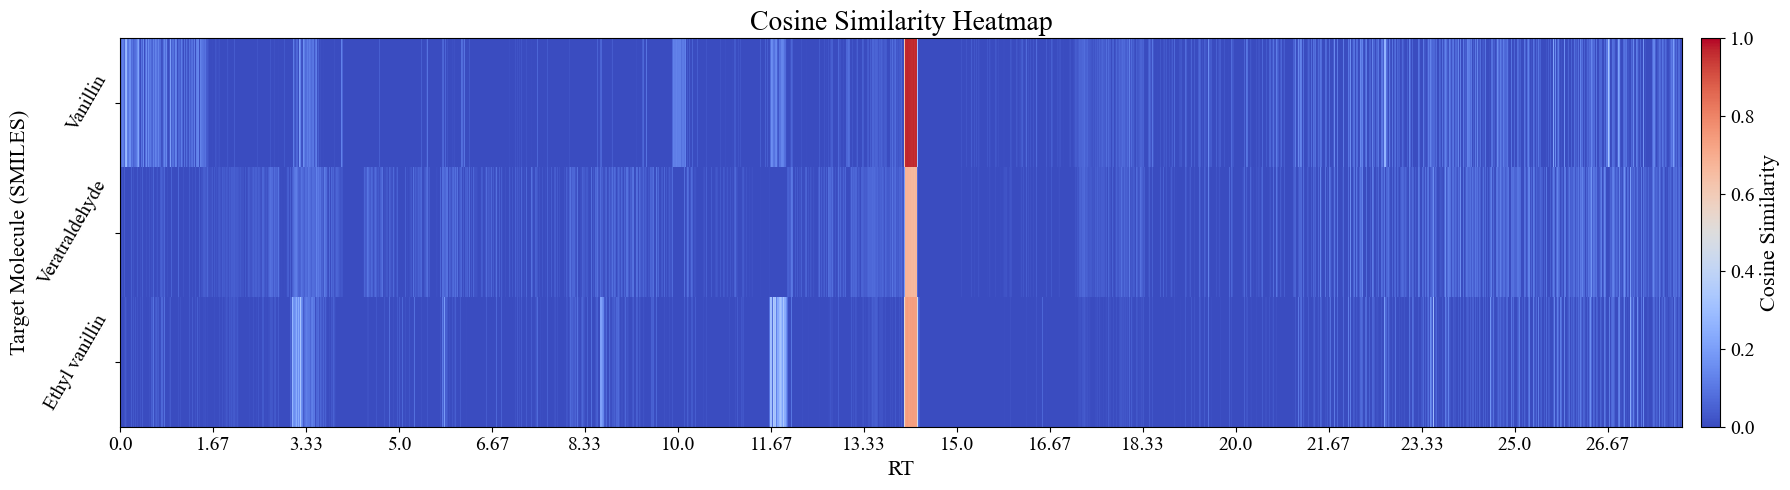

In [9]:
# localization_data = (smiles_list, set1_mass_data.tolist()) 
localization_data = (smiles_list, filtered_set1_data) 
_, all_feature = get_data_and_features(config_path, localization_data, batch_size=128)
smiles_feature, ms_feature, cross_modal_similarity, _, _ = all_feature

cross_modal_similarity[np.isnan(cross_modal_similarity)] = 0
max_distance = cross_modal_similarity.max(axis=1)
argmax_indices = cross_modal_similarity.argmax(axis=1)
rt_list = rt[argmax_indices]
result = np.concatenate([np.round(rt_list, 4).reshape(-1, 1), np.round(max_distance, 4).reshape(-1, 1)], axis=1)
for i in range(len(result)):
    print(f"{result[i][0]:.4f}({result[i][1]:.4f})")

name = ['Vanillin', 'Veratraldehyde', 'Ethyl vanillin']

fig, ax = plt.subplots(figsize=(20, 5))
# im = ax.imshow(cross_modal_similarity, aspect='auto', cmap='viridis', interpolation='nearest', norm=Normalize(vmin=np.percentile(cross_modal_similarity, 95), vmax=cross_modal_similarity.max()))
im = plt.imshow(cross_modal_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=0, vmax=1))

cbar = plt.colorbar(im, pad=0.01)
cbar.set_label('Cosine Similarity', size=16)
cbar.ax.tick_params(labelsize=14)

plt.title('Cosine Similarity Heatmap', fontsize=20)
plt.xlabel('RT', fontsize=16)
plt.ylabel('Target Molecule (SMILES)', fontsize=16)

# for i in range(len(name)):
#     max_rt_idx = argmax_indices[i]
#     max_sim = max_distance[i]
#     ax.scatter(max_rt_idx, i, color='red', s=100, edgecolors='white', zorder=5)
#     ax.text(max_rt_idx + 50, i, f'RT: {rt[max_rt_idx]:.2f}\nSim: {max_sim:.2f}', color='white', ha='left', va='center', fontsize=10)

plt.xticks(
    ticks=np.arange(0, len(rt), step=500), 
    labels=np.round(rt[np.arange(0, len(rt), step=500)], 2),
    fontsize=14
)

plt.yticks(
    ticks=np.arange(0, len(smiles_list), step=1), 
    labels=name,
    rotation=60,
    va='center',
    fontsize=14
)

plt.tight_layout()
# plt.savefig("fig/location/set1_0.8/cross_modal_similarity_heatmap.png", bbox_inches='tight')
plt.show()

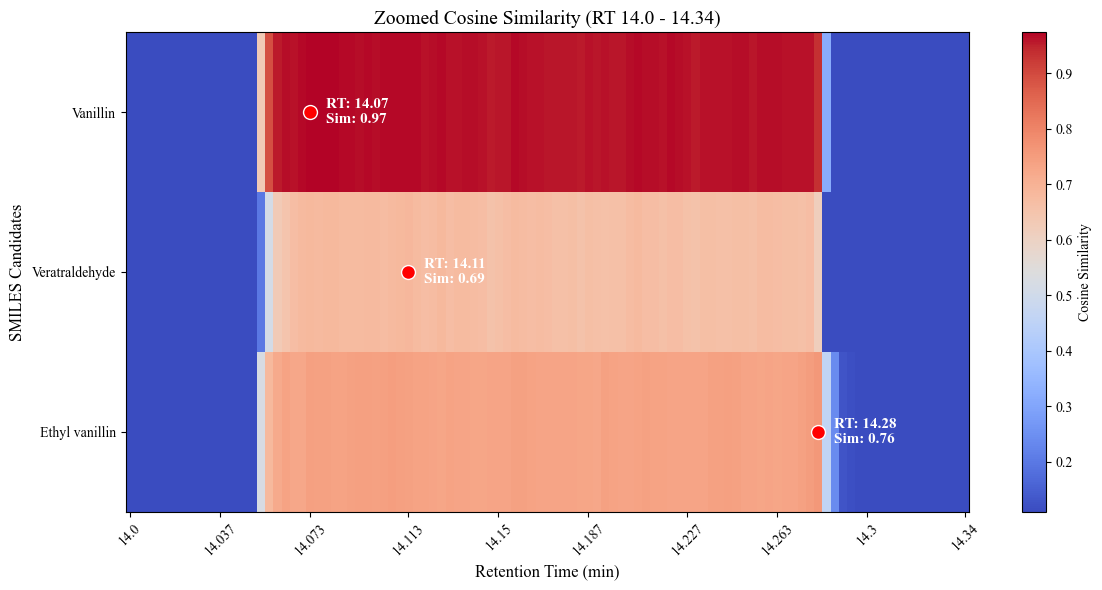

In [ ]:
# 1. Define zoom region (RT range)
if not mask.any():
    print(f"Warning: No data found in range RT {zoom_start}-{zoom_end}")
else:
    # 2. Prepare sliced data
    sub_sim = cross_modal_similarity[:, mask]
    sub_rt = rt[mask]
    start_global_idx = np.where(mask)[0][0]  # Starting global index of current slice

    # 3. Initialize plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Plot heatmap (use 95th percentile as lower bound to improve contrast)
    vmin, vmax = np.percentile(cross_modal_similarity, 95), cross_modal_similarity.max()
    im = ax.imshow(sub_sim, aspect='auto', cmap='coolwarm', interpolation='nearest',
                   norm=Normalize(vmin=vmin, vmax=vmax))

    # 4. Mark maximum value positions for each row
    for row_i, (max_global_idx, max_val) in enumerate(zip(argmax_indices, max_distance)):
        # Check whether the maximum index falls within the current mask range
        if mask[max_global_idx]:
            local_idx = max_global_idx - start_global_idx # Convert to local coordinate
            
            ax.scatter(local_idx, row_i, c='red', s=100, edgecolors='white', zorder=5)
            ax.text(local_idx + 2, row_i, f'RT: {rt[max_global_idx]:.2f}\nSim: {max_val:.2f}', 
                    color='white', va='center', fontweight='bold', fontsize=11)

    # 5. Format axes
    # X-axis: Uniformly sample 10 points for RT display
    tick_indices = np.linspace(0, len(sub_rt) - 1, 10, dtype=int)
    ax.set_xticks(tick_indices)
    ax.set_xticklabels(np.round(sub_rt[tick_indices], 3), rotation=45)
    ax.set_xlabel('Retention Time (min)', fontsize=12)
    
    # Y-axis: Display molecule names
    ax.set_yticks(range(len(name)))
    ax.set_yticklabels(name, fontsize=10)
    ax.set_ylabel('SMILES Candidates', fontsize=12)

    ax.set_title(f'Zoomed Cosine Similarity (RT {zoom_start} - {zoom_end})', fontsize=14)
    plt.colorbar(im, ax=ax, label='Cosine Similarity')
    plt.tight_layout()
    plt.show()

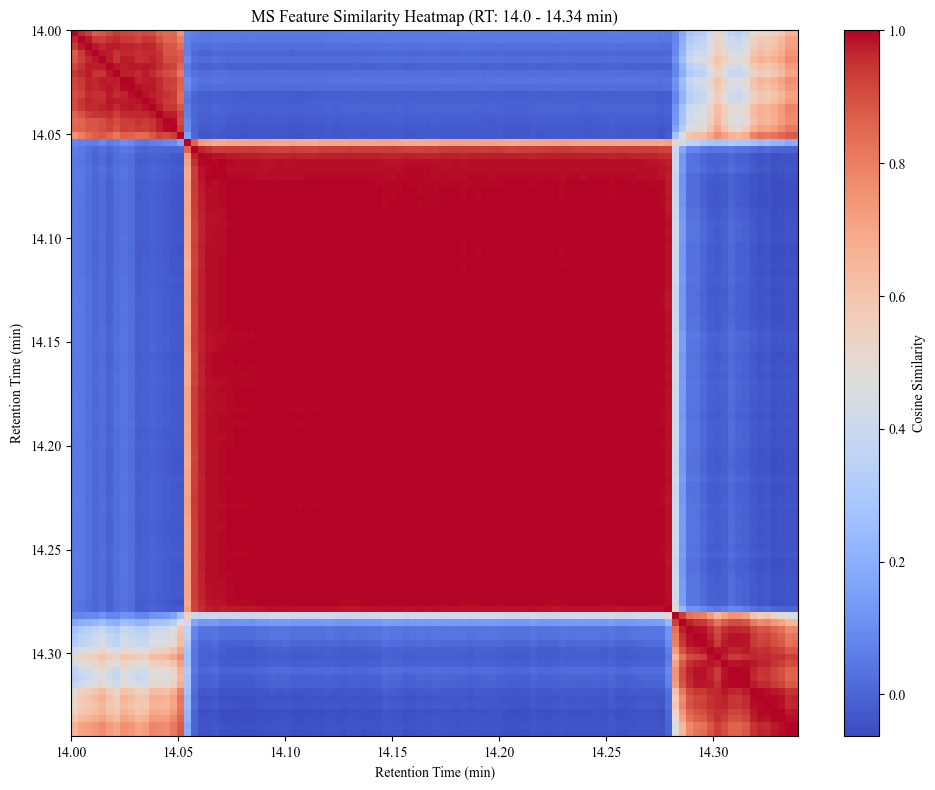

In [ ]:
mask_slice = (rt >= zoom_start) & (rt <= zoom_end)
rt_slice = rt[mask_slice]

if np.sum(mask_slice) == 0:
    print("No data points within the specified range.")
else:
    # Extract corresponding slice of ms_feature
    # Note: Ensure the first dimension of ms_feature matches the length of rt
    if isinstance(ms_feature, torch.Tensor):
        feature_slice = ms_feature[mask_slice]
        # Compute self-similarity (Cosine Similarity)
        # Perform normalization first
        feature_slice_norm = feature_slice / (feature_slice.norm(dim=1, keepdim=True) + 1e-8)
        # Calculate similarity matrix
        similarity_matrix = feature_slice_norm @ feature_slice_norm.T
        similarity_matrix = similarity_matrix.cpu().detach().numpy()
    else:
        # For numpy array input
        feature_slice = ms_feature[mask_slice]
        # Normalization
        norms = np.linalg.norm(feature_slice, axis=1, keepdims=True)
        feature_slice_norm = feature_slice / (norms + 1e-8)
        similarity_matrix = feature_slice_norm @ feature_slice_norm.T

    # Plot heatmap
    plt.figure(figsize=(10, 8))
    # Set axis range to retention time via extent parameter
    # origin='upper' places (0,0) at top-left; cooperate with extent to make Y-axis RT increase from top to bottom
    im = plt.imshow(similarity_matrix, cmap='coolwarm', origin='upper', aspect='auto',
               extent=[rt_slice[0], rt_slice[-1], rt_slice[-1], rt_slice[0]])
    
    plt.colorbar(im, label='Cosine Similarity')
    plt.title(f'MS Feature Similarity Heatmap (RT: {zoom_start} - {zoom_end} min)')
    plt.xlabel('Retention Time (min)')
    plt.ylabel('Retention Time (min)')
    plt.tight_layout()
    plt.show()